# Analysis of n3r6 pipeline run
Initial analysis of antibody panel 2 data

In [2]:
import pathlib as Path
import pandas as pd
import os
import string

import glob

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Metadata
Alena aggregated all of the cell culture group's metadata information: iNDI_Plate_ID, Well_ID, Genotype_Name, JAX_ID, Batch_Info, Cell_Line_Info\

In [3]:
all_automated_plates_combined_fn = "/data/CARDPB2/iNDI/Production/metadata/AbPanel2/AbPanel2_automated_plates_combined.csv"
all_automated_plates_combined = pd.read_csv(all_automated_plates_combined_fn)
all_automated_plates_combined['JAX_ID'] = (
    all_automated_plates_combined['JAX_ID'].str.replace('JAX_ID_', '', regex=False)
)

JAX_catalog_fn = "/data/CARDPB2/iNDI/Production/metadata/JAX_iPSC_Catalog.tsv"
JAX_catalog = pd.read_csv(JAX_catalog_fn, sep='\t')

# clean up all_automated_plates_combined$JAX_ID column to remove 'JAX_ID_" to merge with JAX_catalog$JAX_Code
merged = all_automated_plates_combined.merge(
    JAX_catalog,
    left_on='JAX_ID',
    right_on='JAX_Code',
    how='left',
)
print(merged.head())

                                        Cell_Line_ID iNDI_Plate_ID Well_ID  \
0                 JAX_ID_JIPSC001002\nFUS R495X HOM     INDI00004D     A01   
1  JAX_ID_JIPSC001072\nVCP R159H REV \nLow counts...    INDI00004D     A02   
2              JAX_ID_JIPSC001000\nParental  ID:5424    INDI00004D     A03   
3                 JAX_ID_JIPSC001006\nFUS R495X REV     INDI00004D     A04   
4                  JAX_ID_JIPSC001070\nVCP R159H HET    INDI00004D     A05   

   Genotype_Name       JAX_ID Batch_Info     JAX_Code      Gene Variant  \
0  FUS R495X HOM  JIPSC001002        NaN  JIPSC001002       FUS   R495X   
1  VCP R159H REV  JIPSC001072        NaN  JIPSC001072       VCP   R159H   
2       Parental  JIPSC001000    ID:5424  JIPSC001000  KOLF2.1J     NaN   
3  FUS R495X REV  JIPSC001006        NaN  JIPSC001006       FUS   R495X   
4  VCP R159H HET  JIPSC001070        NaN  JIPSC001070       VCP   R159H   

  Genotype      Gene_Var_Type  
0  SNV/SNV  FUS_R495X_SNV/SNV  
1   REV/WT   VCP

In [4]:
files = glob.glob("/data/kelpschdj/iNDI/Production/outputs/run_20260921_131450_n3r6/nuclei_filtered/*_nuclei_filtered.parquet")

parts = []
for f in files:
    part = pd.read_parquet(f)
    parts.append(part)
    print(f"{os.path.basename(f)}: {len(part)} rows")

df = pd.concat(parts, ignore_index=True)

print(f"\nLoaded {len(files)} files, {len(df)} total rows")
print(df.head())
print(df.columns.tolist())

plate_id_fn = "/data/CARDPB2/iNDI/Production/metadata/indi_plateID_to_folderID.csv"
plate_id = pd.read_csv(plate_id_fn)
print(plate_id.head())

df = df.merge(
    plate_id,
    left_on="Measurement_ID",
    right_on="Folder_ID",
    how="left",
    validate="many_to_one",
)

# Row/Column are 1-based ints from the filename parse (r01c01...).
df["Well_ID"] = (
    df["Row"].astype(int).map(lambda r: string.ascii_uppercase[r - 1])
    + df["Column"].astype(int).map(lambda c: f"{c:02d}")
)

df = df.merge(
    merged[["iNDI_Plate_ID", "Well_ID", "Gene_Var_Type", "Genotype_Name", "Gene", "Variant"]],
    on=["iNDI_Plate_ID", "Well_ID"],
    how="left",
    validate="many_to_one",
)

# sanity check the join
n_unmatched = df["Gene_Var_Type"].isna().sum()
print(f"{n_unmatched} nuclei rows didn't match a genotype")
if n_unmatched:
    print(df.loc[df["Gene_Var_Type"].isna(), ["iNDI_Plate_ID", "Well_ID"]].drop_duplicates().head(20))

print(df.head())

0acd04e9-3bc9-400b-8557-3f5b4123caaa_nuclei_filtered.parquet: 162722 rows
106c8b69-e11f-4698-abd6-d4d01ec5fbb2_nuclei_filtered.parquet: 82775 rows
48fb9a14-1123-488d-9b56-3befe944f933_nuclei_filtered.parquet: 224594 rows
72a1d9f3-277a-4abd-bf55-cbbc07152dff_nuclei_filtered.parquet: 68159 rows
84809677-0531-486c-b79f-e25c7ef9a7c6_nuclei_filtered.parquet: 133722 rows
85cc6732-9e29-40ad-9ec1-e94b9f334ebe_nuclei_filtered.parquet: 87508 rows
9ed6a73a-227d-45a5-90dd-5c87fa906bea_nuclei_filtered.parquet: 171742 rows
a9b2a502-ad2f-4ee9-85ba-10df3cea3b46_nuclei_filtered.parquet: 237108 rows
cba96cb5-1337-4136-ab55-482e1bc9bed3_nuclei_filtered.parquet: 182607 rows
cd5eb985-d862-4c96-8b57-570f462ee2fa_nuclei_filtered.parquet: 268737 rows
d5847ccd-b4ba-4ce9-a214-ea68b817e7f0_nuclei_filtered.parquet: 129787 rows
d5b2e3eb-3b91-4619-8c74-846bbcd92bd4_nuclei_filtered.parquet: 190444 rows
e61d5e8c-faef-4c2c-8df6-6cc72032f19e_nuclei_filtered.parquet: 176028 rows

Loaded 13 files, 2115933 total rows
   l

In [5]:
print(f"Total number of images: {df[['filename', 'Plate_ID']].drop_duplicates().shape[0]}")
print(f"Total number of nuclei (before QC): {len(df)}")
print(f"Total number of nuclei (after QC): {len(df[df['selected'] == True])}")

Total number of images: 209261
Total number of nuclei (before QC): 2115933
Total number of nuclei (after QC): 1064806


In [6]:
group_cols = ["iNDI_Plate_ID", "Gene_Var_Type"]

# "Before" = every nucleus in the table; "after" = only selected.
before = (
    df.groupby(group_cols)
      .agg(images_before=("image_name", "nunique"),
           wells_before=("Well_ID", "nunique"),
           nuclei_before=("image_name", "size"))
)

after = (
    df[df["selected"]]
      .groupby(group_cols)
      .agg(images_after=("image_name", "nunique"),
           wells_after=("Well_ID", "nunique"),
           nuclei_after=("image_name", "size"))
)

summary = (
    before.join(after, how="left")
          .fillna({"images_after": 0, "wells_after": 0, "nuclei_after": 0})
          .astype({"images_after": int, "wells_after": int, "nuclei_after": int})
          .reset_index()
)

# reorder for readability
summary = summary[[
    "iNDI_Plate_ID", "Gene_Var_Type",
    "wells_before", "wells_after",
    "images_before", "images_after",
    "nuclei_before", "nuclei_after",
]]

# print grouped by plate
for plate, grp in summary.groupby("iNDI_Plate_ID"):
    print(f"\n=== iNDI_Plate_ID: {plate} ===")
    print(grp.drop(columns="iNDI_Plate_ID").to_string(index=False))

# summary.to_csv(
#     "/data/kelpschdj/iNDI/Production/outputs/filtering_summary.csv",
#     index=False,
# )
print("Wrote filtering_summary.csv")


=== iNDI_Plate_ID: INDI00004D ===
    Gene_Var_Type  wells_before  wells_after  images_before  images_after  nuclei_before  nuclei_after
 FUS_R495X_REV/WT            48           48           2850          2815          27215         15721
FUS_R495X_SNV/SNV            48           48           2877          2842          29264         15048
 FUS_R495X_SNV/WT            48           48           2849          2822          33164         17512
         KOLF2.1J            96           96           5797          5747          68711         36908
 VCP_R159H_REV/WT            48           48           2158          2062           8972          6066
VCP_R159H_SNV/SNV            48           48           2917          2906          31516         17624
 VCP_R159H_SNV/WT            47           47           2835          2824          38266         19570

=== iNDI_Plate_ID: INDI00008D ===
       Gene_Var_Type  wells_before  wells_after  images_before  images_after  nuclei_before  nuclei_after


# Nucleus feature analysis

Set up PCAs for nucleus features across genotypes\
Considering parentals and well-level data aggregation\
Manual only and autonomous only PCAs\
Work on Asp Pause ID assessment here

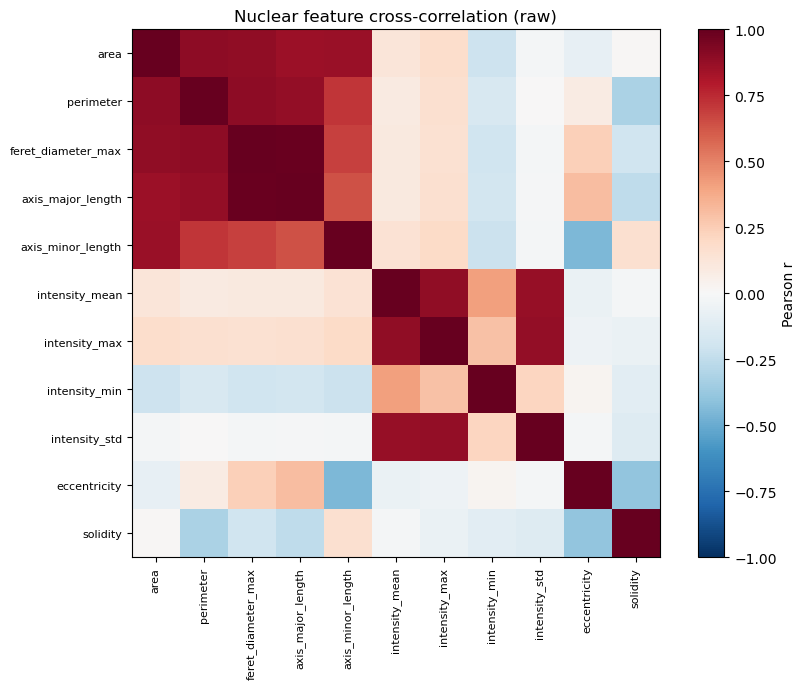

Highly correlated pairs (|r| > 0.9):
  +0.989  feret_diameter_max     axis_major_length

Using FEATURES: ['area', 'intensity_mean', 'intensity_std', 'eccentricity', 'solidity', 'aspect_ratio']


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# df is your merged nuclear-feature dataframe (metadata already joined).

# ---------------------------------------------------------------
# STEP 0 — candidate nuclear features (regionprops from script 1)
# ---------------------------------------------------------------
CANDIDATE_FEATURES = [
    # size
    "area", "perimeter", "feret_diameter_max",
    "axis_major_length", "axis_minor_length",
    # intensity (DAPI)
    "intensity_mean", "intensity_max", "intensity_min", "intensity_std",
    # shape
    "eccentricity", "solidity",
]
CANDIDATE_FEATURES = [c for c in CANDIDATE_FEATURES if c in df.columns]

# ---------------------------------------------------------------
# STEP 1 — cross-correlation (raw, pre-scaling)
# ---------------------------------------------------------------
X_all = df[CANDIDATE_FEATURES].replace([np.inf, -np.inf], np.nan)
corr = X_all.corr(method="pearson")

plt.figure(figsize=(9, 7))
im = plt.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
plt.xticks(range(len(CANDIDATE_FEATURES)), CANDIDATE_FEATURES, rotation=90, fontsize=8)
plt.yticks(range(len(CANDIDATE_FEATURES)), CANDIDATE_FEATURES, fontsize=8)
plt.colorbar(im, label="Pearson r")
plt.title("Nuclear feature cross-correlation (raw)")
plt.tight_layout(); plt.show()

hi = (corr.abs() > 0.9) & (corr.abs() < 1.0)
pairs = [
    (a, b, round(corr.loc[a, b], 3))
    for i, a in enumerate(CANDIDATE_FEATURES)
    for b in CANDIDATE_FEATURES[i + 1:]
    if hi.loc[a, b]
]
print("Highly correlated pairs (|r| > 0.9):")
for a, b, r in sorted(pairs, key=lambda t: -abs(t[2])):
    print(f"  {r:+.3f}  {a:22s} {b}")

# ---------------------------------------------------------------
# STEP 2 — pruned FEATURES
# The size cluster (area, perimeter, feret, both axes) is heavily collinear.
# Keep `area` as the size representative + a shape-aspect ratio that captures
# elongation independent of size. Drop the redundant size columns.
# ---------------------------------------------------------------
df["aspect_ratio"] = df["axis_minor_length"] / df["axis_major_length"]

FEATURES = [
    "area",
    "intensity_mean", "intensity_std",
    "eccentricity", "solidity", "aspect_ratio",
]
FEATURES = [c for c in FEATURES if c in df.columns]
print("\nUsing FEATURES:", FEATURES)

Dropped 0 rows with NaN/inf; 2115933 remain


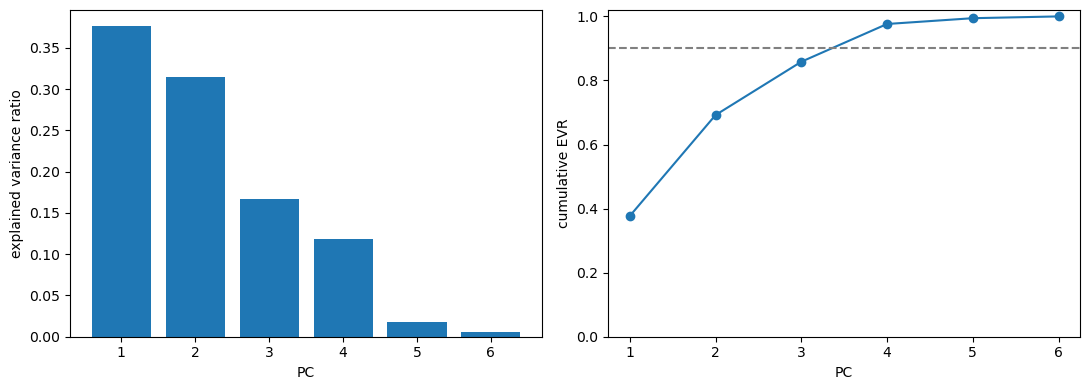

EVR: [0.377 0.315 0.166 0.118 0.018 0.006]
cumulative: [0.377 0.692 0.858 0.976 0.994 1.   ]
                  PC1    PC2    PC3    PC4    PC5    PC6
area            0.084  0.071  0.987  0.054  0.108  0.013
intensity_mean  0.085  0.696  0.012  0.138 -0.699 -0.010
intensity_std   0.028  0.701 -0.130  0.010  0.701  0.009
eccentricity   -0.631  0.017  0.025  0.338 -0.002  0.697
solidity        0.421 -0.135 -0.084  0.887  0.091 -0.043
aspect_ratio    0.640 -0.026 -0.045 -0.276 -0.013  0.715


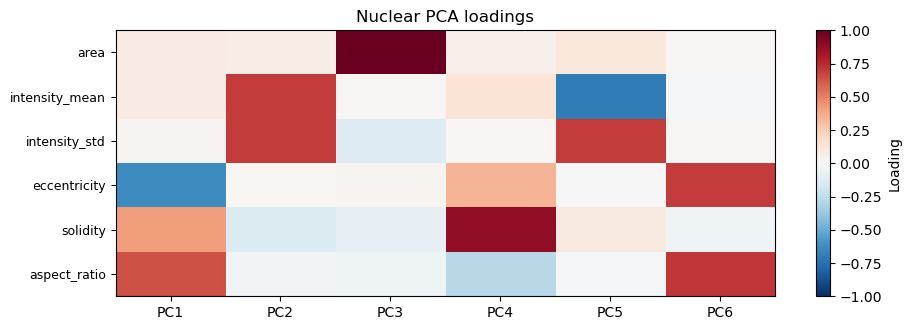

In [8]:
# ---------------------------------------------------------------
# NaN/inf handling
# ---------------------------------------------------------------
before = len(df)
X_df = df[FEATURES].replace([np.inf, -np.inf], np.nan)
keep = X_df.notna().all(axis=1)
df = df[keep].reset_index(drop=True)
X_df = X_df[keep].reset_index(drop=True)
print(f"Dropped {before - len(df)} rows with NaN/inf; {len(df)} remain")

# ---------------------------------------------------------------
# scale + PCA
# ---------------------------------------------------------------
X = StandardScaler().fit_transform(X_df.values)
pca = PCA(n_components=len(FEATURES))
scores = pca.fit_transform(X)
for i in range(scores.shape[1]):
    df[f"PC{i+1}"] = scores[:, i]

# scree
ev = pca.explained_variance_ratio_
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(range(1, len(ev) + 1), ev)
ax[0].set_xlabel("PC"); ax[0].set_ylabel("explained variance ratio")
ax[1].plot(range(1, len(ev) + 1), np.cumsum(ev), marker="o")
ax[1].axhline(0.9, ls="--", c="gray"); ax[1].set_xlabel("PC")
ax[1].set_ylabel("cumulative EVR"); ax[1].set_ylim(0, 1.02)
plt.tight_layout(); plt.show()
print("EVR:", ev.round(3))
print("cumulative:", np.cumsum(ev).round(3))

# loadings
loadings = pd.DataFrame(
    pca.components_.T, index=FEATURES,
    columns=[f"PC{i+1}" for i in range(len(FEATURES))],
)
print(loadings.round(3))

n_show = min(6, len(FEATURES))
plt.figure(figsize=(1.6 * n_show, 0.4 * len(FEATURES) + 1))
im = plt.imshow(loadings.iloc[:, :n_show], cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
plt.xticks(range(n_show), [f"PC{i+1}" for i in range(n_show)])
plt.yticks(range(len(FEATURES)), FEATURES, fontsize=9)
plt.colorbar(im, label="Loading")
plt.title("Nuclear PCA loadings")
plt.tight_layout(); plt.show()

13 plates in this run:
['INDI00004D', 'INDI00008D', 'INDI00016D', 'INDI00020D', 'INDI00024D', 'INDI00028D', 'INDI00036D', 'INDI00040D', 'INDI00044D', 'INDI00048D', 'INDI00050D', 'INDI00054D', 'INDIMS0000']
All 13 plates have a color.


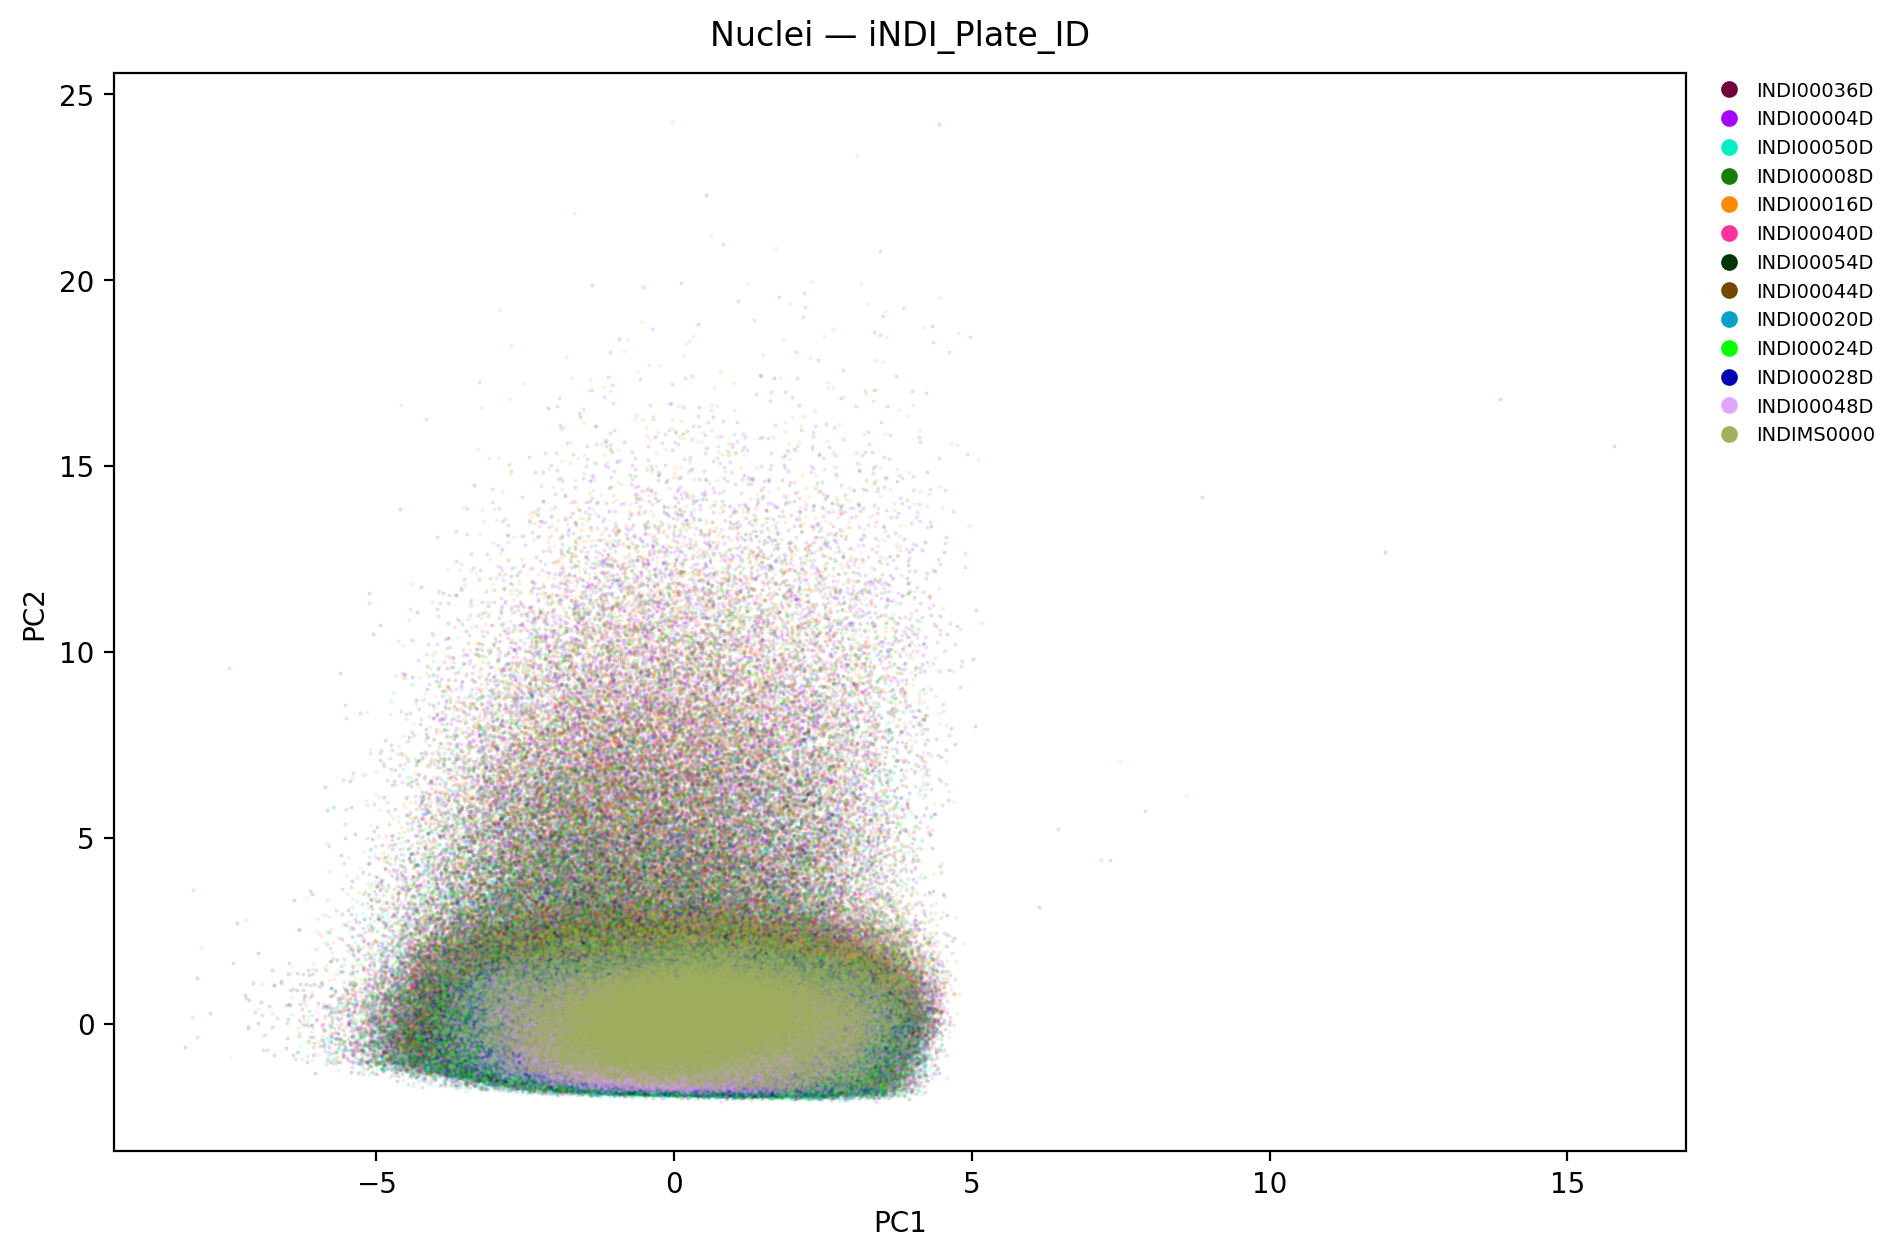

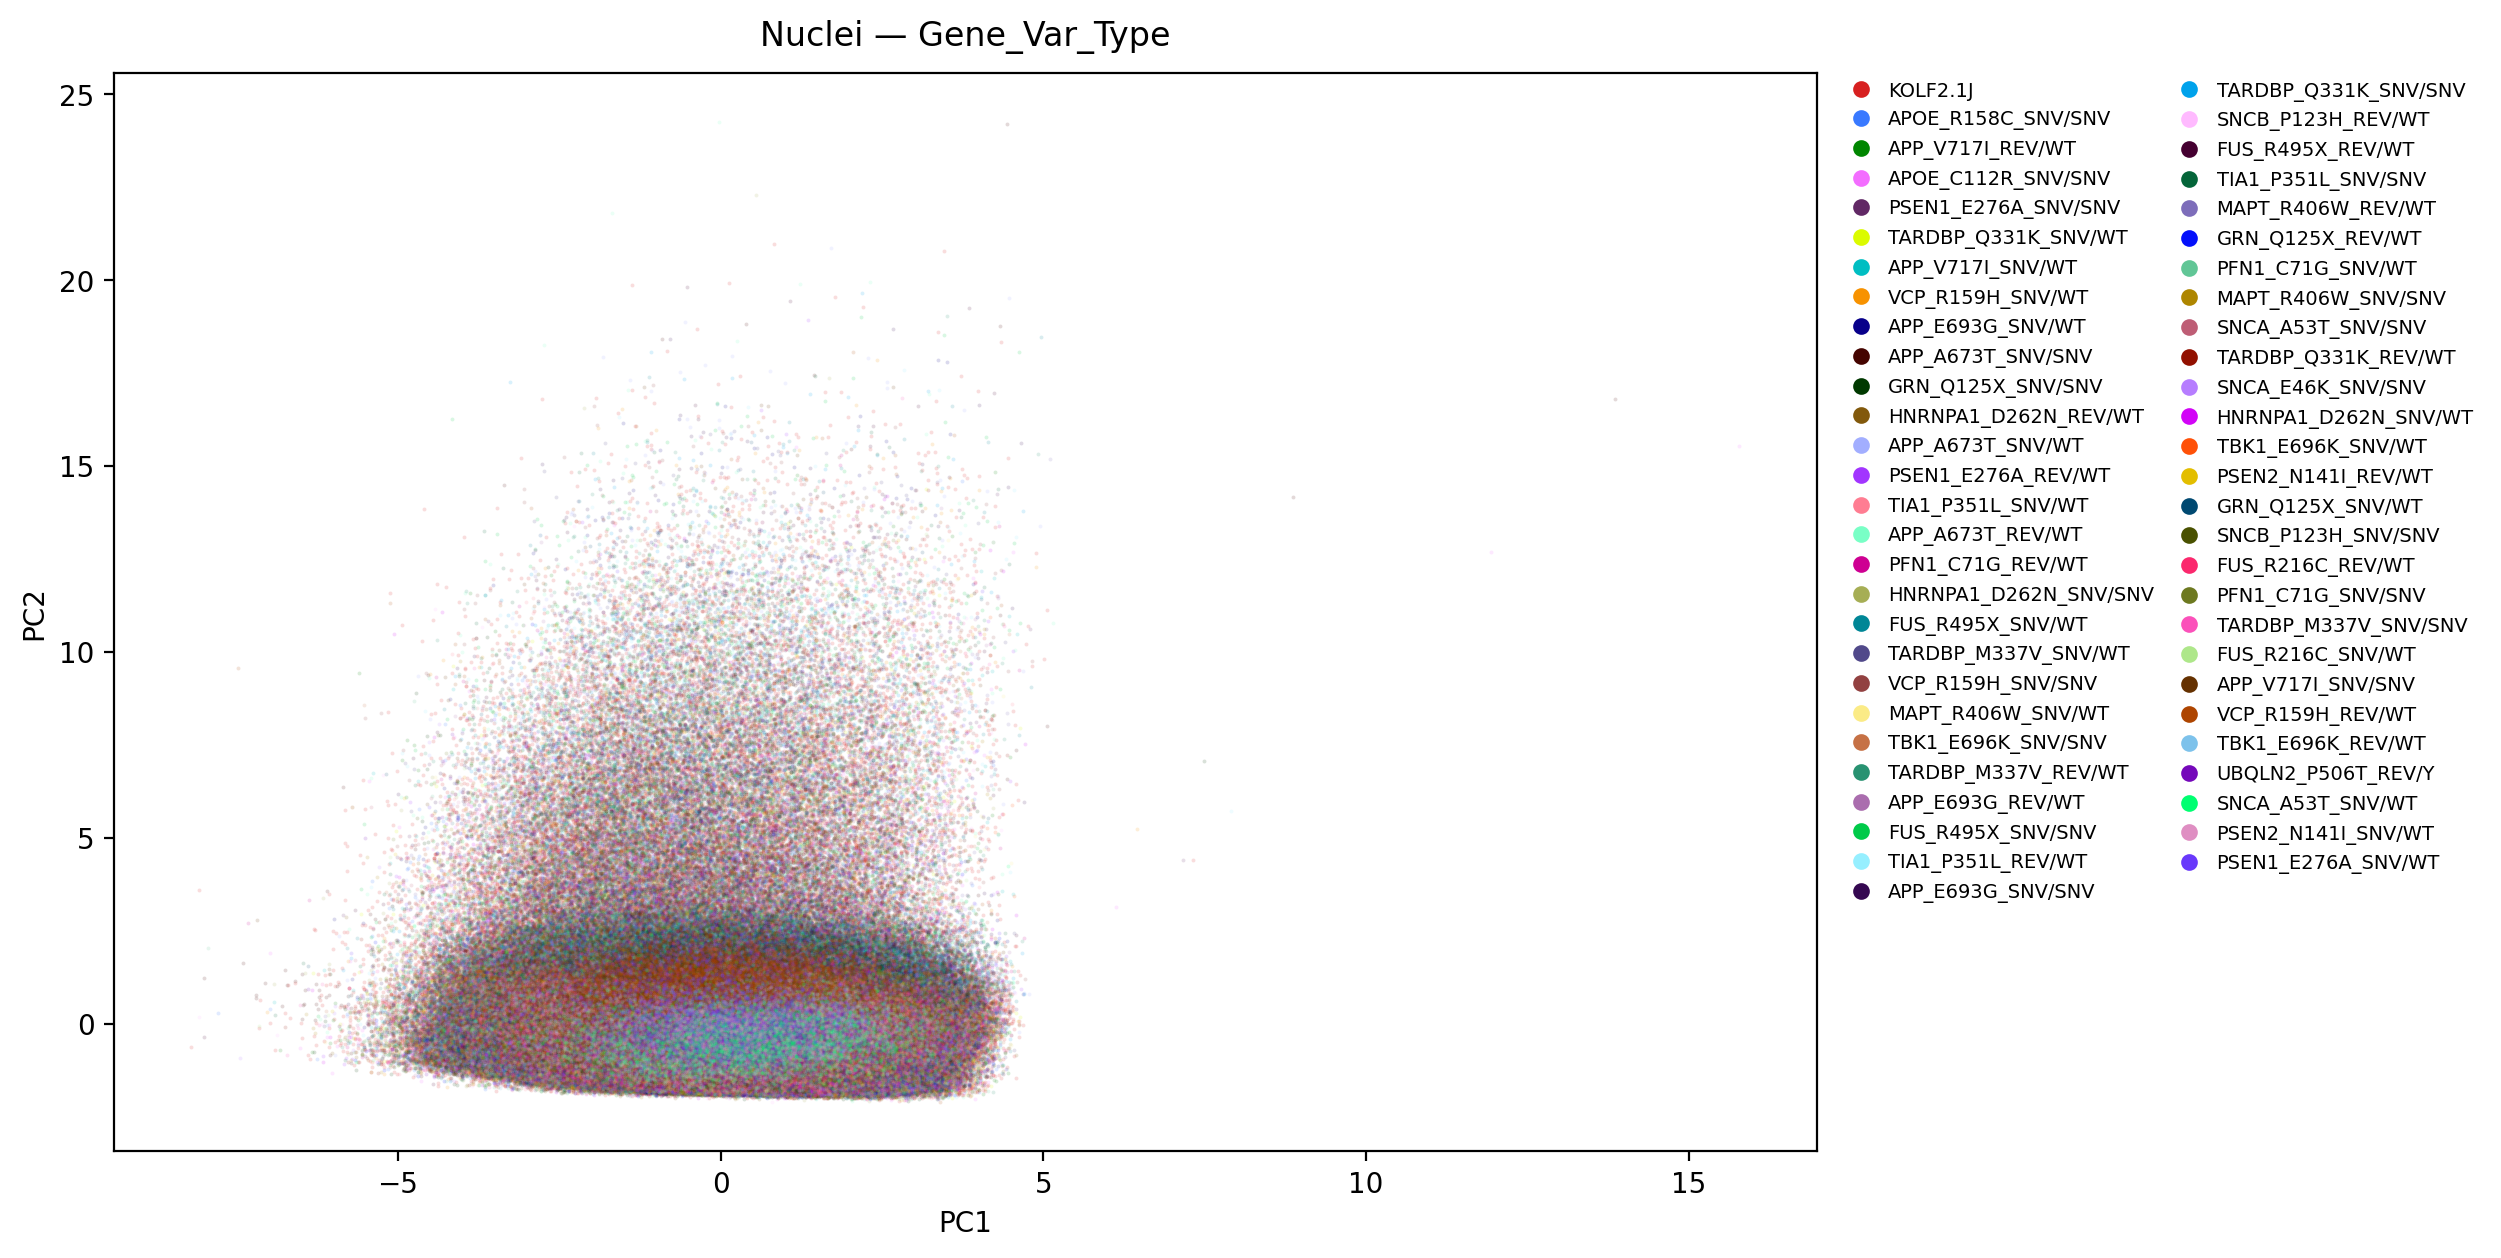

In [9]:
from matplotlib.lines import Line2D
from matplotlib.colors import ListedColormap
import seaborn as sns
import glasbey

import glasbey
from matplotlib.colors import ListedColormap

# derive plate list from the data, not a hardcoded set
unique_plate_ids = sorted(df["iNDI_Plate_ID"].dropna().unique())
print(f"{len(unique_plate_ids)} plates in this run:")
print(unique_plate_ids)

plate_palette_raw = glasbey.create_palette(
    palette_size=max(len(unique_plate_ids), 1),
    hue_bounds=(60, 500.0), chroma_bounds=(40, 130),
)
colors_plates = [ListedColormap(plate_palette_raw)(i)
                 for i in range(len(plate_palette_raw))]
plate_palette = {pid: colors_plates[i] for i, pid in enumerate(unique_plate_ids)}

# glasbey palette for genotypes (high-cardinality, no fixed mapping)
geno_palette_raw = glasbey.create_palette(
    palette_size=64, hue_bounds=(0.0, 360.0), chroma_bounds=(40, 90)
)
geno_colors = [ListedColormap(geno_palette_raw)(i)
               for i in range(len(geno_palette_raw))]

def pca_scatter(df, color_col, pcx="PC1", pcy="PC2", palette=None,
                s=2, alpha=0.15, figsize=(10, 7), legend_ncol=1,
                title=None, show_legend=True):
    fig, ax = plt.subplots(figsize=figsize, dpi=200)
    fig.subplots_adjust(right=0.78)
    vals = df[color_col].astype("object")
    cats = vals.value_counts().index.tolist()

    if palette is not None:
        colors = [palette.get(c, "#808080") for c in cats]
    elif color_col == "Gene_Var_Type":
        colors = [geno_colors[i % len(geno_colors)] for i in range(len(cats))]
    else:
        colors = sns.color_palette("husl", n_colors=len(cats))

    for c, col in zip(cats, colors):
        m = vals == c
        ax.scatter(df.loc[m, pcx], df.loc[m, pcy], s=s, alpha=alpha,
                   color=col, linewidths=0, rasterized=True)
    ax.set_xlabel(pcx); ax.set_ylabel(pcy)
    ax.set_title(title or f"PCA of {color_col}", pad=10)
    if show_legend:
        handles = [Line2D([0], [0], marker="o", linestyle="", markersize=5,
                   markerfacecolor=col, markeredgecolor=col, label=str(c))
                   for c, col in zip(cats, colors)]
        ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1.0),
                  frameon=False, fontsize=7, ncol=legend_ncol,
                  borderaxespad=0.0, handletextpad=0.4, columnspacing=0.8)
    plt.show()


# guard: plates in data with no palette color
plates_in_data = set(df["iNDI_Plate_ID"].dropna().unique())
missing = plates_in_data - set(plate_palette)
print(f"[warning] plates with no color: {sorted(missing)}" if missing
      else f"All {len(plates_in_data)} plates have a color.")

df_shuf = df.sample(frac=1, random_state=0).reset_index(drop=True)
pca_scatter(df_shuf, "iNDI_Plate_ID", palette=plate_palette, figsize=(12, 7),
            title="Nuclei — iNDI_Plate_ID")
pca_scatter(df_shuf, "Gene_Var_Type", figsize=(13, 7), legend_ncol=2,
            title="Nuclei — Gene_Var_Type")

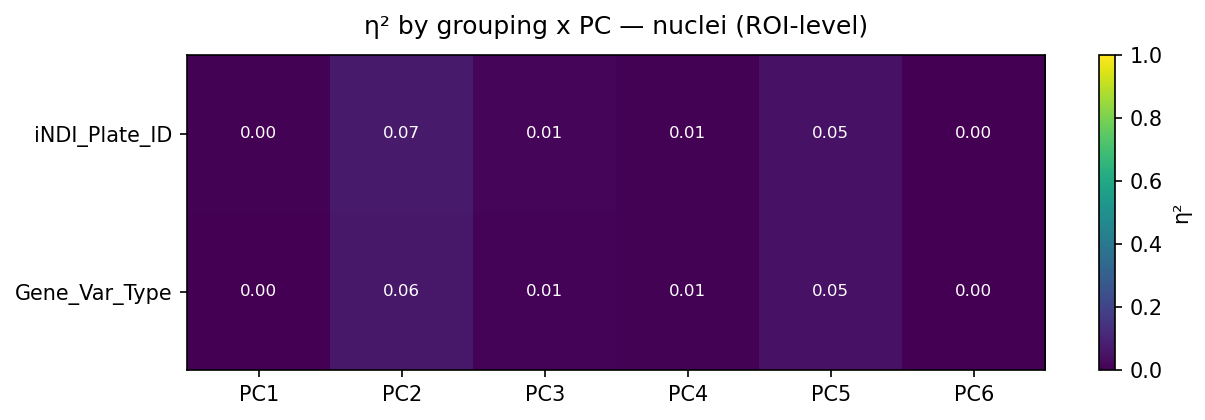

In [10]:
def eta_squared(values, groups):
    values = np.asarray(values, dtype=float)
    mask = np.isfinite(values)
    values, groups = values[mask], np.asarray(groups)[mask]
    if values.size == 0:
        return np.nan
    grand = values.mean()
    ss_total = ((values - grand) ** 2).sum()
    ss_between = 0.0
    for g in pd.unique(groups):
        v = values[groups == g]
        if v.size == 0:            # guard: skip empty groups
            continue
        ss_between += len(v) * (v.mean() - grand) ** 2
    return ss_between / ss_total if ss_total > 0 else np.nan


def eta_heatmap(data, group_cols, n_pcs=None, title="η² by grouping x PC", annot=True):
    pc_cols = sorted([c for c in data.columns if c.startswith("PC")],
                     key=lambda s: int(s[2:]))
    if n_pcs is not None:
        pc_cols = pc_cols[:n_pcs]
    group_cols = [g for g in group_cols if g in data.columns]
    mat = pd.DataFrame(index=group_cols, columns=pc_cols, dtype=float)
    for gc in group_cols:
        groups = data[gc].to_numpy()
        for pc in pc_cols:
            mat.loc[gc, pc] = eta_squared(data[pc].to_numpy(), groups)
    fig, ax = plt.subplots(figsize=(1.1 * len(pc_cols) + 2, 0.7 * len(group_cols) + 1.5), dpi=150)
    im = ax.imshow(mat.values.astype(float), cmap="viridis", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(len(pc_cols))); ax.set_xticklabels(pc_cols)
    ax.set_yticks(range(len(group_cols))); ax.set_yticklabels(group_cols)
    plt.colorbar(im, ax=ax, label="η²")
    ax.set_title(title, pad=10)
    if annot:
        for i in range(len(group_cols)):
            for j in range(len(pc_cols)):
                v = mat.iloc[i, j]
                if pd.notna(v):
                    ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                            color="white" if v < 0.6 else "black", fontsize=8)
    plt.tight_layout(); plt.show()
    return mat

# Structure dropped (single channel). Batch drivers that matter for nuclei:
GROUP_COLS = ["prep_method", "iNDI_Plate_ID", "Gene_Var_Type"]
eta_full = eta_heatmap(df, GROUP_COLS, n_pcs=6, title="η² by grouping x PC — nuclei (ROI-level)")

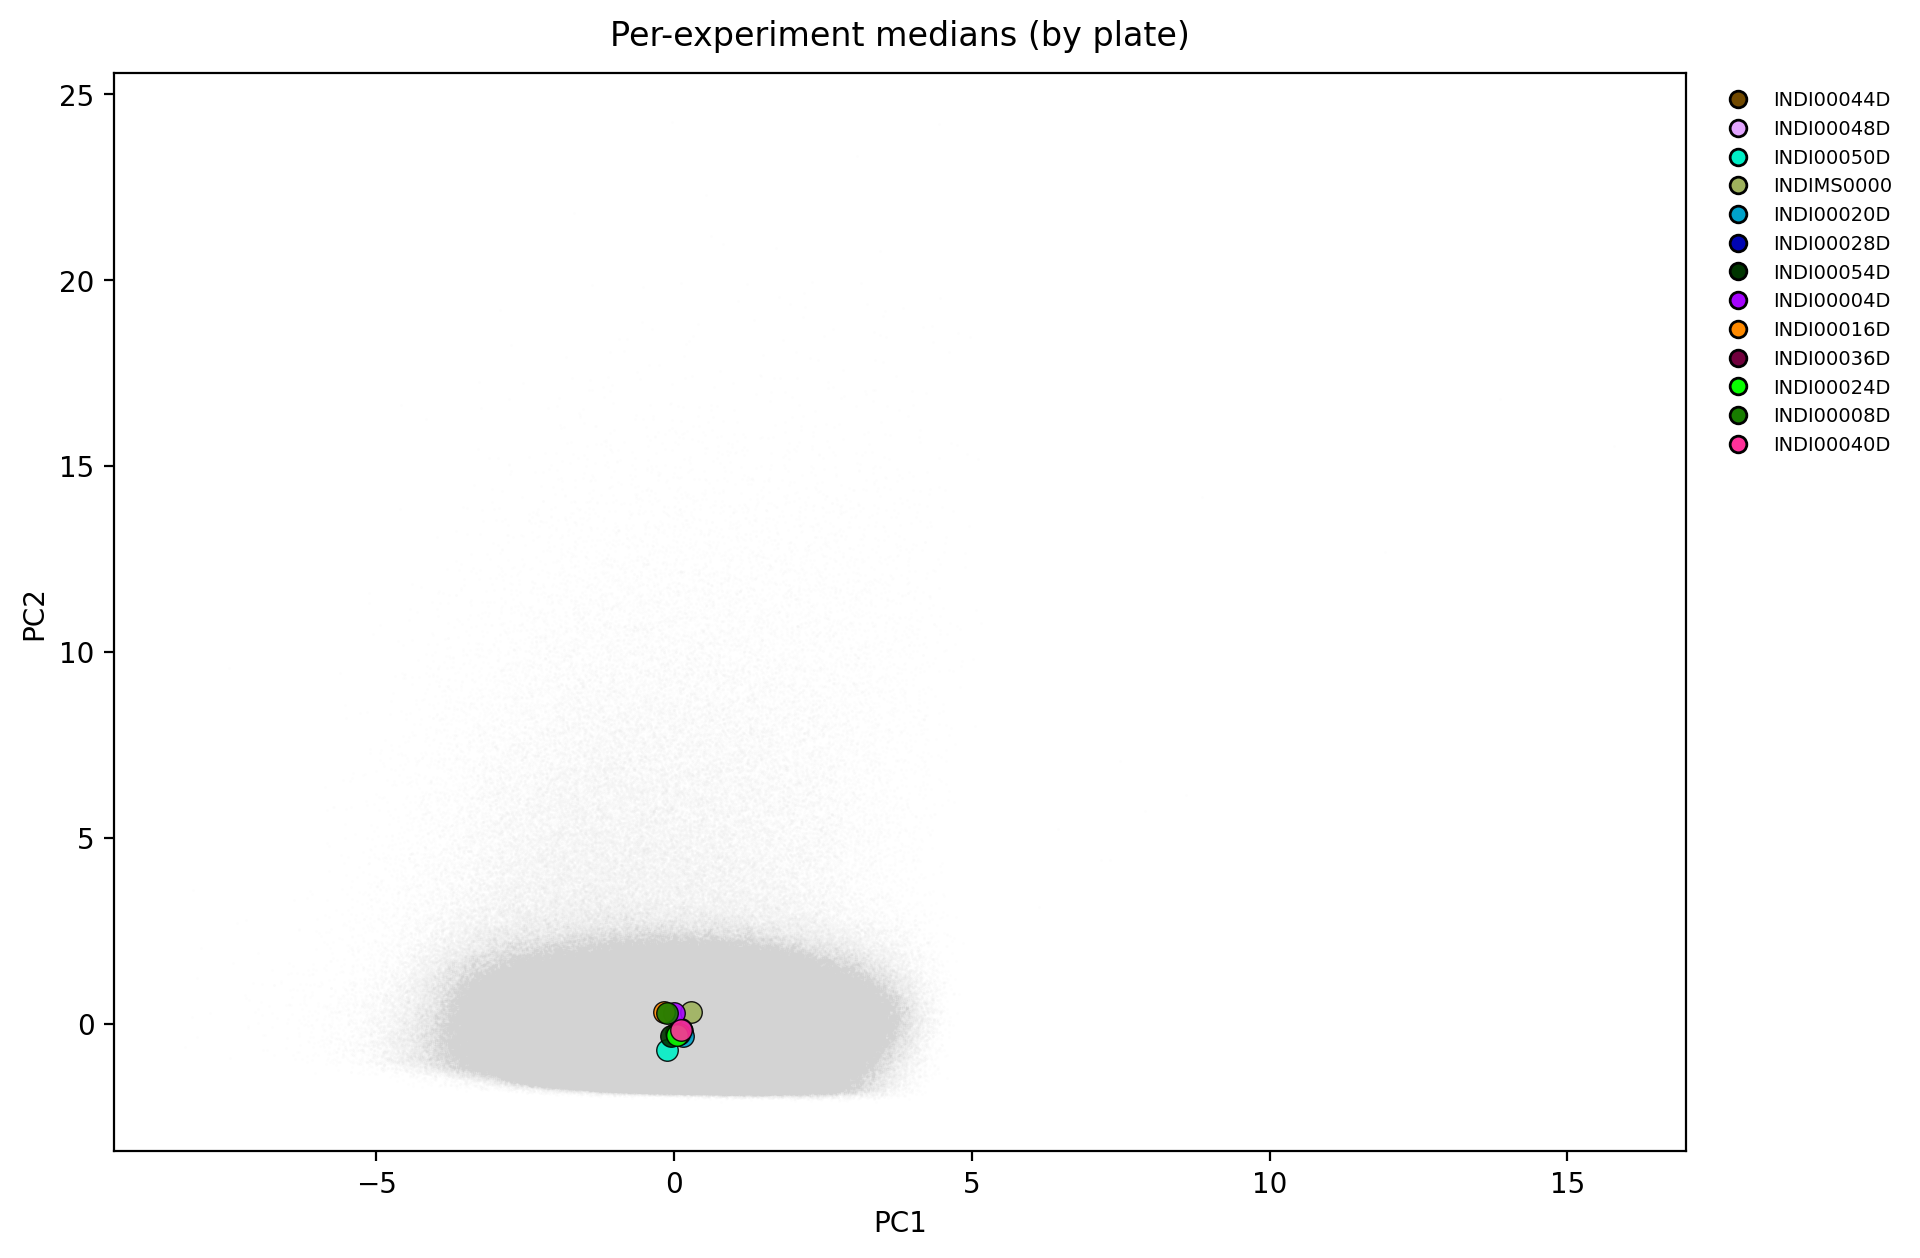

Std of per-experiment centroids (batch magnitude):
PC1    0.127
PC2    0.318
PC3    0.088
dtype: float64


In [11]:
def centroid_overlay(df, color_col, group_keys, pcx="PC1", pcy="PC2",
                     palette=None, stat="median", bg_frac=1.0, s_centroid=60,
                     figsize=(10, 7), legend_ncol=1, title=None,
                     bg_s=1, bg_alpha=0.03):
    fig, ax = plt.subplots(figsize=figsize, dpi=200)
    fig.subplots_adjust(right=0.78)
    bg = df.sample(frac=bg_frac, random_state=0) if bg_frac < 1.0 else df
    ax.scatter(bg[pcx], bg[pcy], s=bg_s, alpha=bg_alpha, color="lightgray",
               linewidths=0, rasterized=True)
    agg_spec = {pcx: stat, pcy: stat}
    if color_col not in group_keys:
        agg_spec[color_col] = "first"
    cent = df.groupby(group_keys).agg(agg_spec).reset_index()
    vals = cent[color_col].astype("object")
    cats = vals.value_counts().index.tolist()
    if palette is not None:
        colors = [palette.get(c, "#808080") for c in cats]
    else:
        colors = sns.color_palette("husl", n_colors=len(cats))
    for c, col in zip(cats, colors):
        m = vals == c
        ax.scatter(cent.loc[m, pcx], cent.loc[m, pcy], s=s_centroid, color=col,
                   edgecolor="k", linewidths=0.5, alpha=0.9)
    ax.set_xlabel(pcx); ax.set_ylabel(pcy)
    ax.set_title(title or f"Per-group {stat} centroids ({color_col})", pad=10)
    handles = [Line2D([0], [0], marker="o", linestyle="", markersize=6,
               markerfacecolor=col, markeredgecolor="k", label=str(c))
               for c, col in zip(cats, colors)]
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1.0),
              frameon=False, fontsize=7, ncol=legend_ncol)
    plt.show()
    return cent

# per-experiment medians, colored by plate — spread = batch variation
centroid_overlay(df, color_col="iNDI_Plate_ID", group_keys=["Measurement_ID"],
                 palette=plate_palette, title="Per-experiment medians (by plate)",
                 figsize=(12, 7))

# batch magnitude: std of per-experiment centroids (no Structure split now)
cent = df.groupby("Measurement_ID")[["PC1", "PC2", "PC3"]].median()
print("Std of per-experiment centroids (batch magnitude):")
print(cent.std().round(3))

Genotype_Name: 0 well(s) with >1 value
iNDI_Plate_ID: 0 well(s) with >1 value

Image-level: 209261 rows (24181 images)
Well-level: 3953 rows
Well-level EVR: [0.418 0.329 0.152 0.069 0.027 0.005] | cumulative: [0.418 0.747 0.899 0.968 0.995 1.   ]


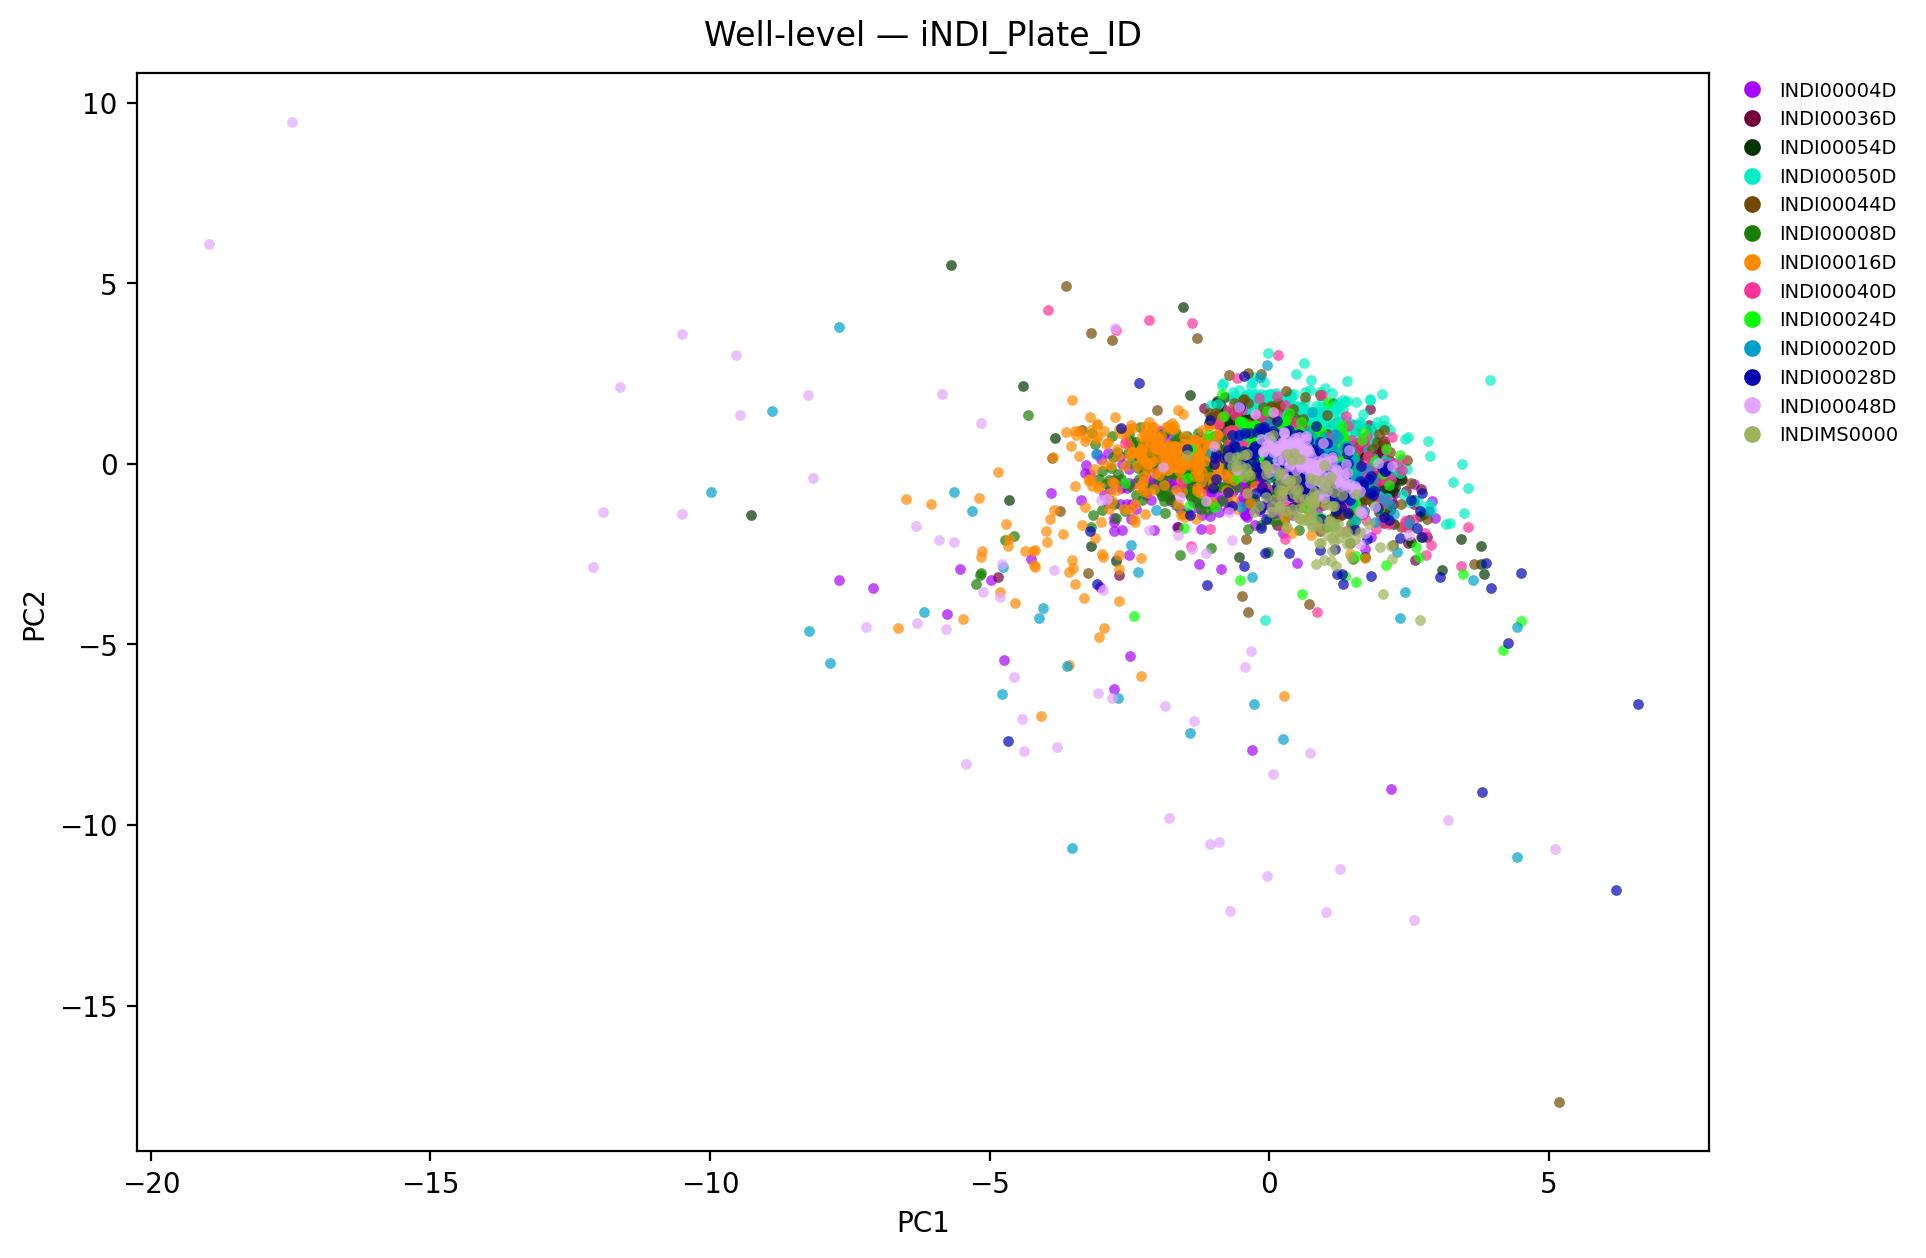

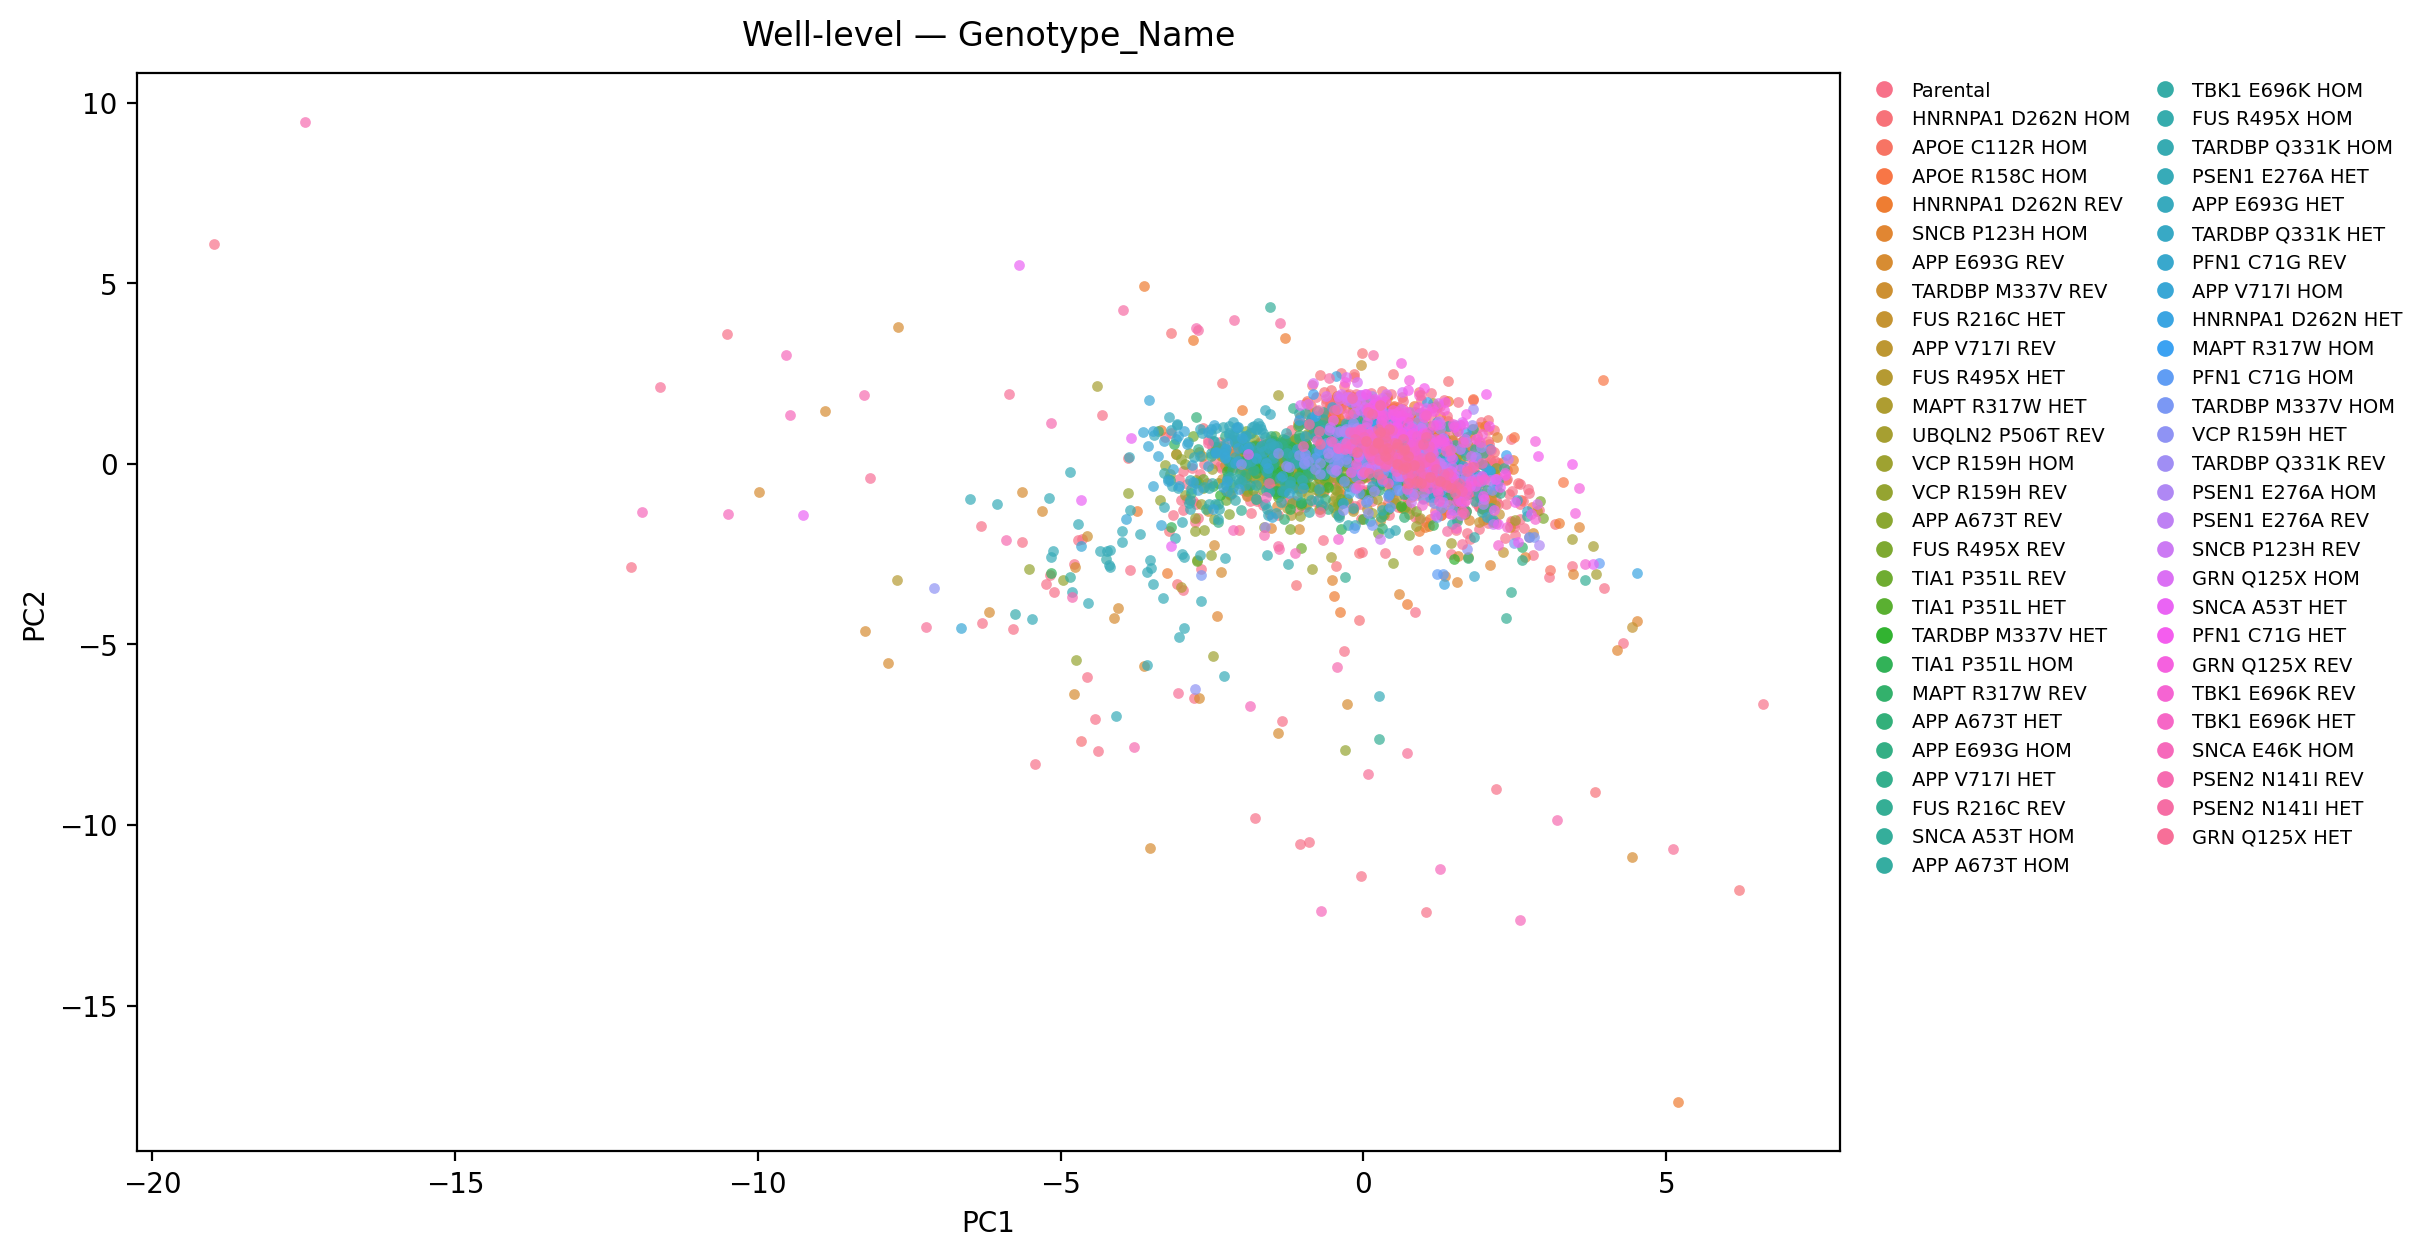

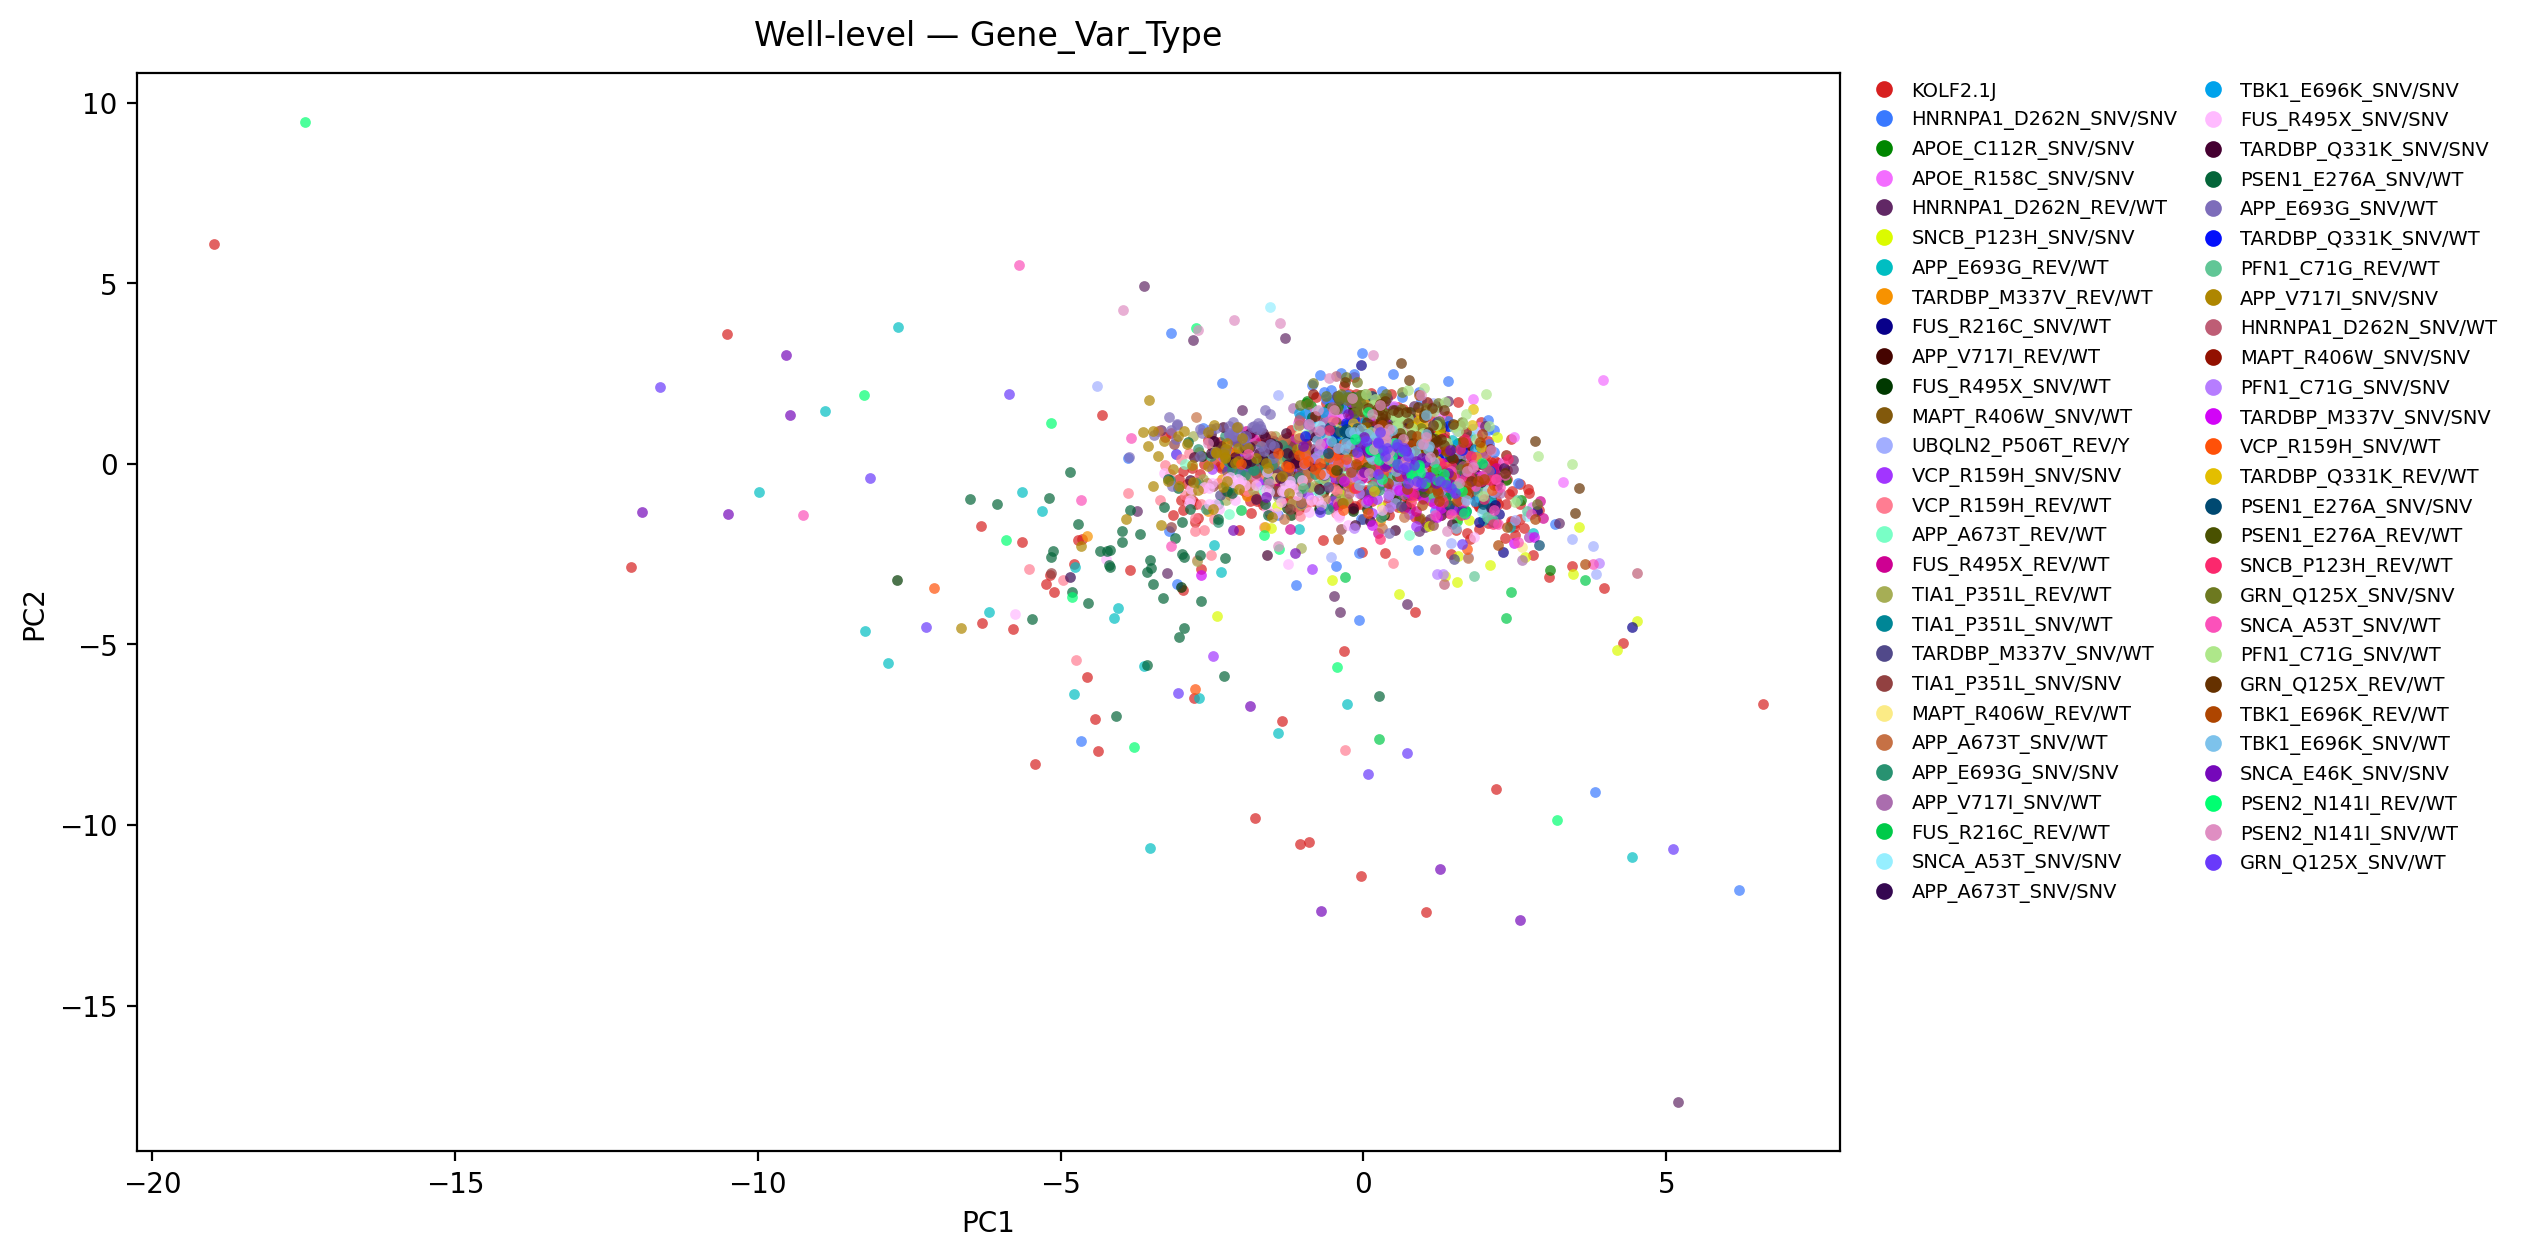

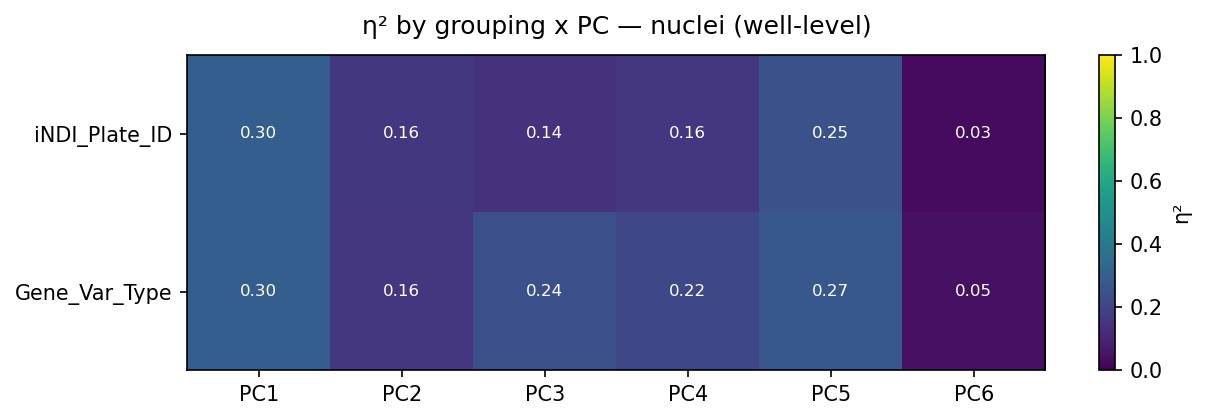

,PC1,PC2,PC3,PC4,PC5,PC6
iNDI_Plate_ID,0.300246,0.162316,0.141139,0.160015,0.246417,0.029558
Gene_Var_Type,0.299903,0.160132,0.244032,0.216927,0.271500,0.045347


In [12]:
# Nuclei keys: image = image_name, well = Measurement_ID + subdirectory.
# No Structure grouping.
WELL_KEYS = ["Measurement_ID", "subdirectory"]
IMAGE_KEY = "image_name"

GROUP_KEYS = [*WELL_KEYS, IMAGE_KEY]
DROP_COLS = set(FEATURES) | {f"PC{i+1}" for i in range(20)} | set(GROUP_KEYS) \
            | {"label", "filename", "filepath"}
META_COLS = [c for c in df.columns if c not in DROP_COLS]

# safety: metadata carried by .first() should be invariant within a well
for col in ["Genotype_Name", "iNDI_Plate_ID", "prep_method"]:
    if col in df.columns:
        n_bad = (df.groupby(WELL_KEYS)[col].nunique() > 1).sum()
        print(f"{col}: {n_bad} well(s) with >1 value{'  <-- CHECK' if n_bad else ''}")

# stage 1: median across nuclei within each image
agg_image = {**{f: "median" for f in FEATURES}, **{m: "first" for m in META_COLS}}
image_level = df.groupby(GROUP_KEYS, as_index=False).agg(agg_image)
print(f"\nImage-level: {len(image_level)} rows ({df[IMAGE_KEY].nunique()} images)")

# stage 2: mean across images within each well
agg_well = {**{f: "mean" for f in FEATURES}, **{m: "first" for m in META_COLS}}
well_level = image_level.groupby(WELL_KEYS, as_index=False).agg(agg_well)
print(f"Well-level: {len(well_level)} rows")

# refit PCA on well-level profiles
Xw_df = well_level[FEATURES].replace([np.inf, -np.inf], np.nan)
keep = Xw_df.notna().all(axis=1)
well_level = well_level[keep].reset_index(drop=True)
Xw_df = Xw_df[keep].reset_index(drop=True)
Xw = StandardScaler().fit_transform(Xw_df.values)
pca_well = PCA(n_components=len(FEATURES))
scores_w = pca_well.fit_transform(Xw)
for i in range(scores_w.shape[1]):
    well_level[f"PC{i+1}"] = scores_w[:, i]
evw = pca_well.explained_variance_ratio_
print("Well-level EVR:", evw.round(3), "| cumulative:", np.cumsum(evw).round(3))

well_shuf = well_level.sample(frac=1, random_state=0).reset_index(drop=True)
pca_scatter(well_shuf, "iNDI_Plate_ID", palette=plate_palette, s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — iNDI_Plate_ID")
pca_scatter(well_shuf, "Genotype_Name", s=15, alpha=0.7, figsize=(13, 7),
            legend_ncol=2, title="Well-level — Genotype_Name")
pca_scatter(well_shuf, "Gene_Var_Type", s=15, alpha=0.7, figsize=(13, 7),
            legend_ncol=2, title="Well-level — Gene_Var_Type")

# well-level η² (does plate structure persist after aggregation?)
eta_heatmap(well_level, ["prep_method", "iNDI_Plate_ID", "Gene_Var_Type"],
            n_pcs=6, title="η² by grouping x PC — nuclei (well-level)")

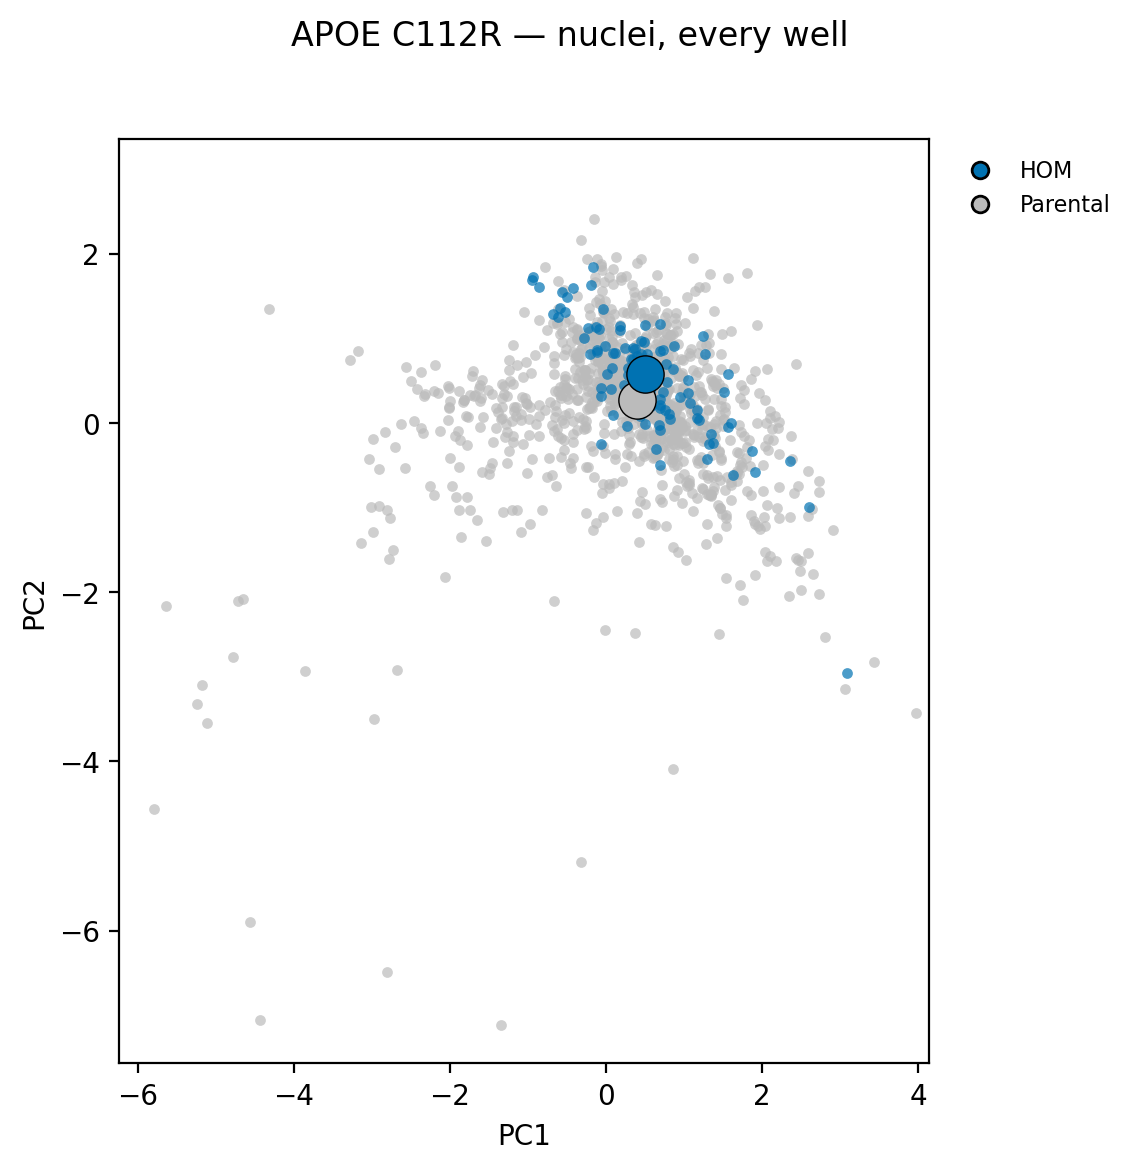

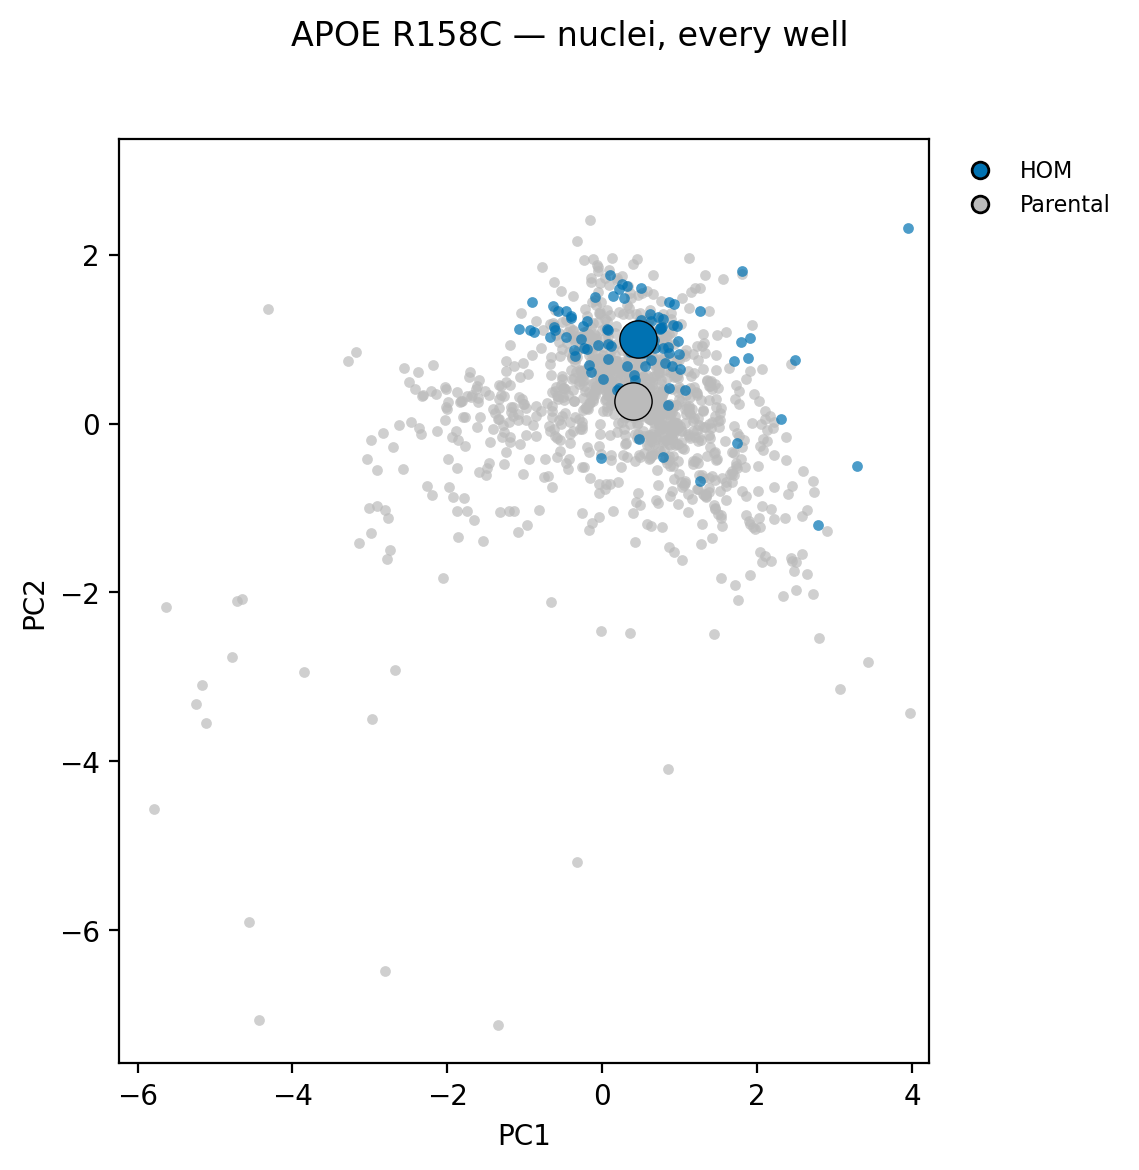

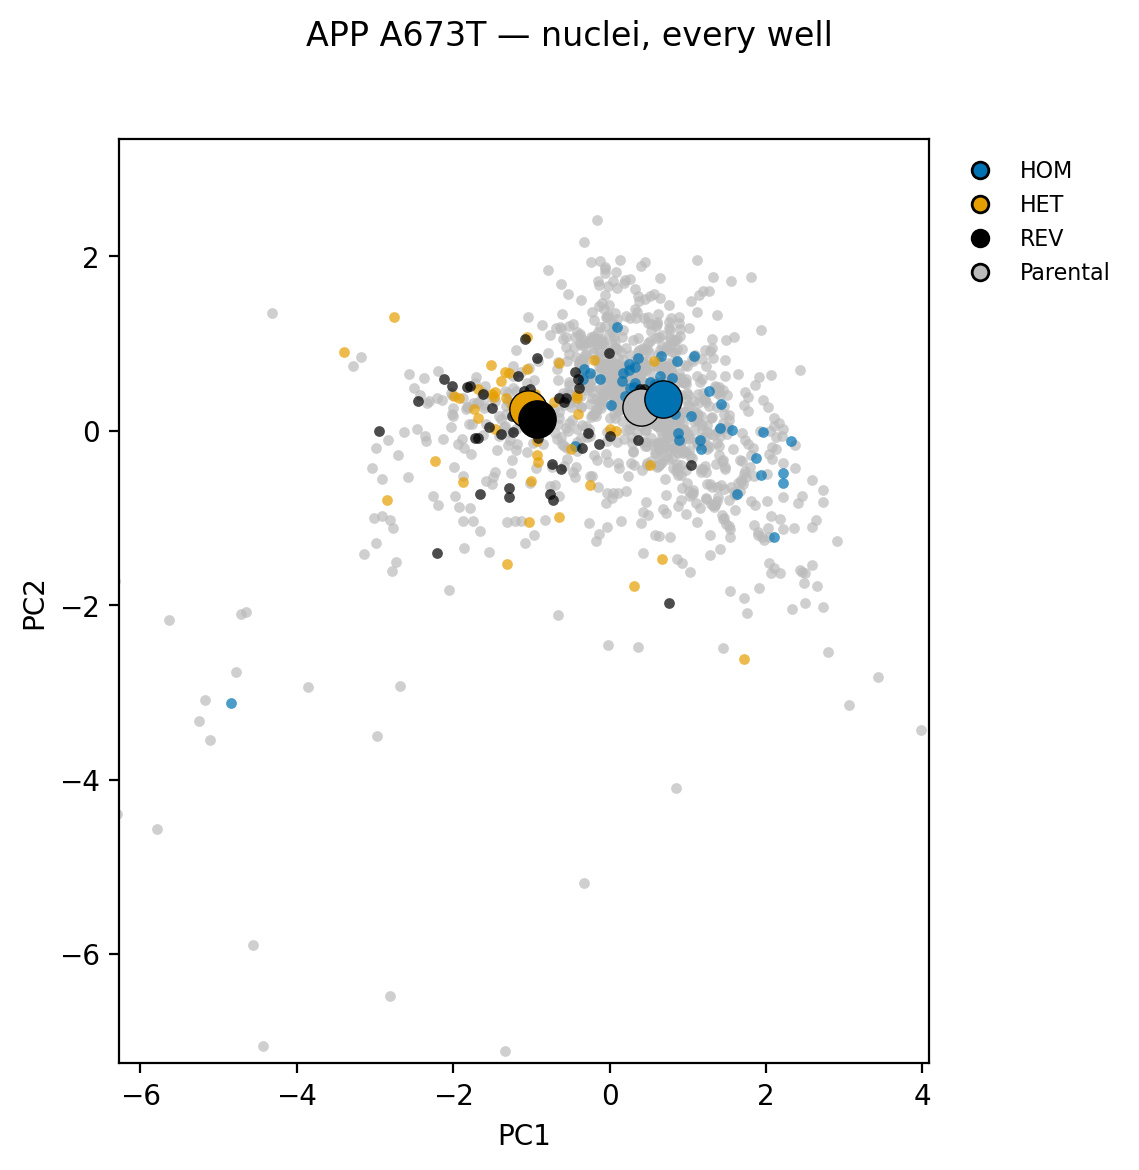

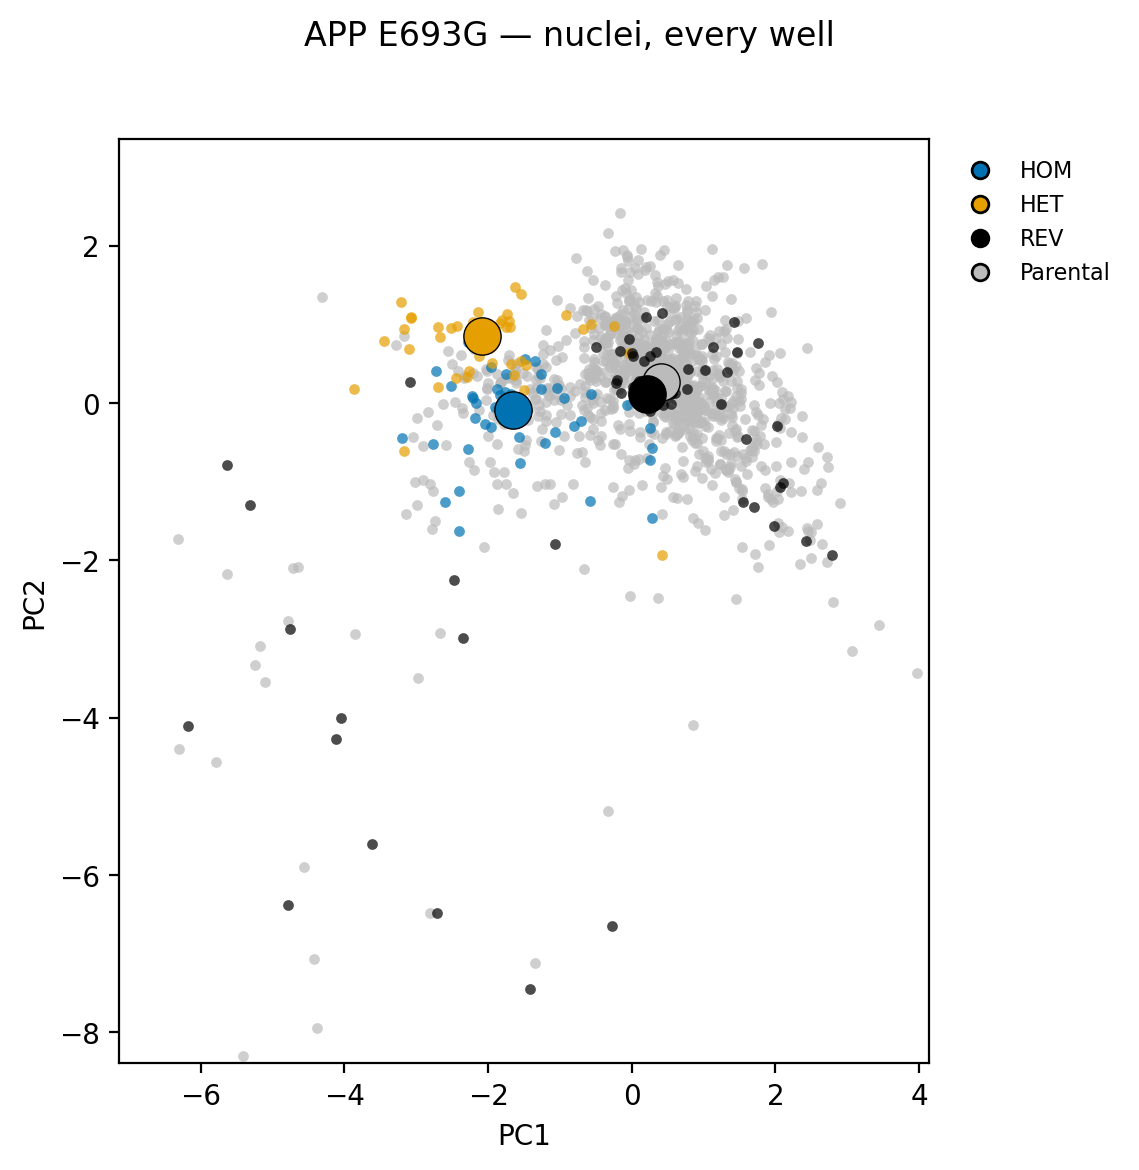

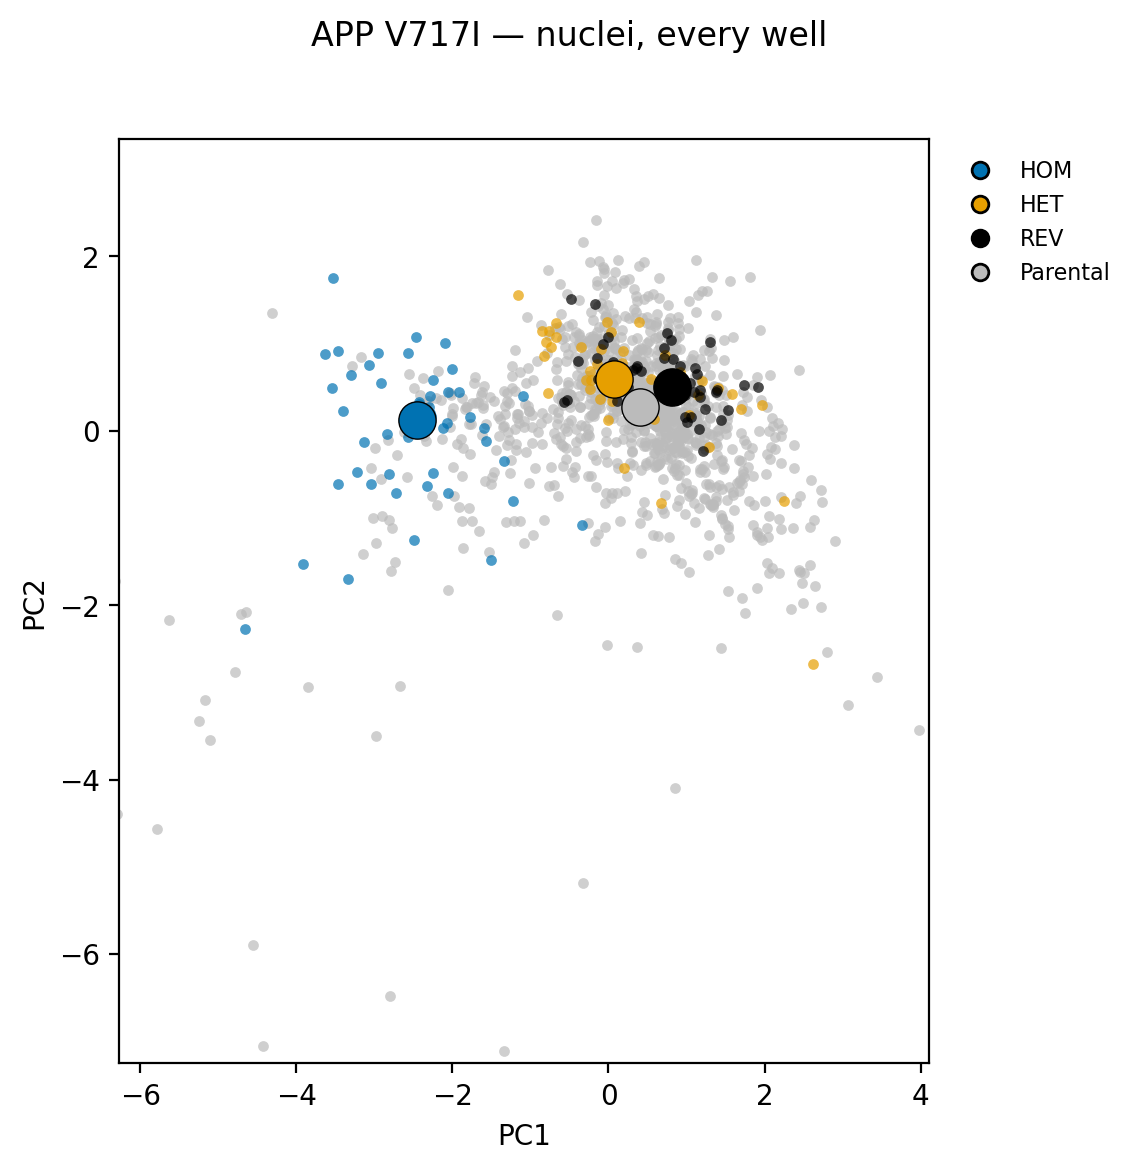

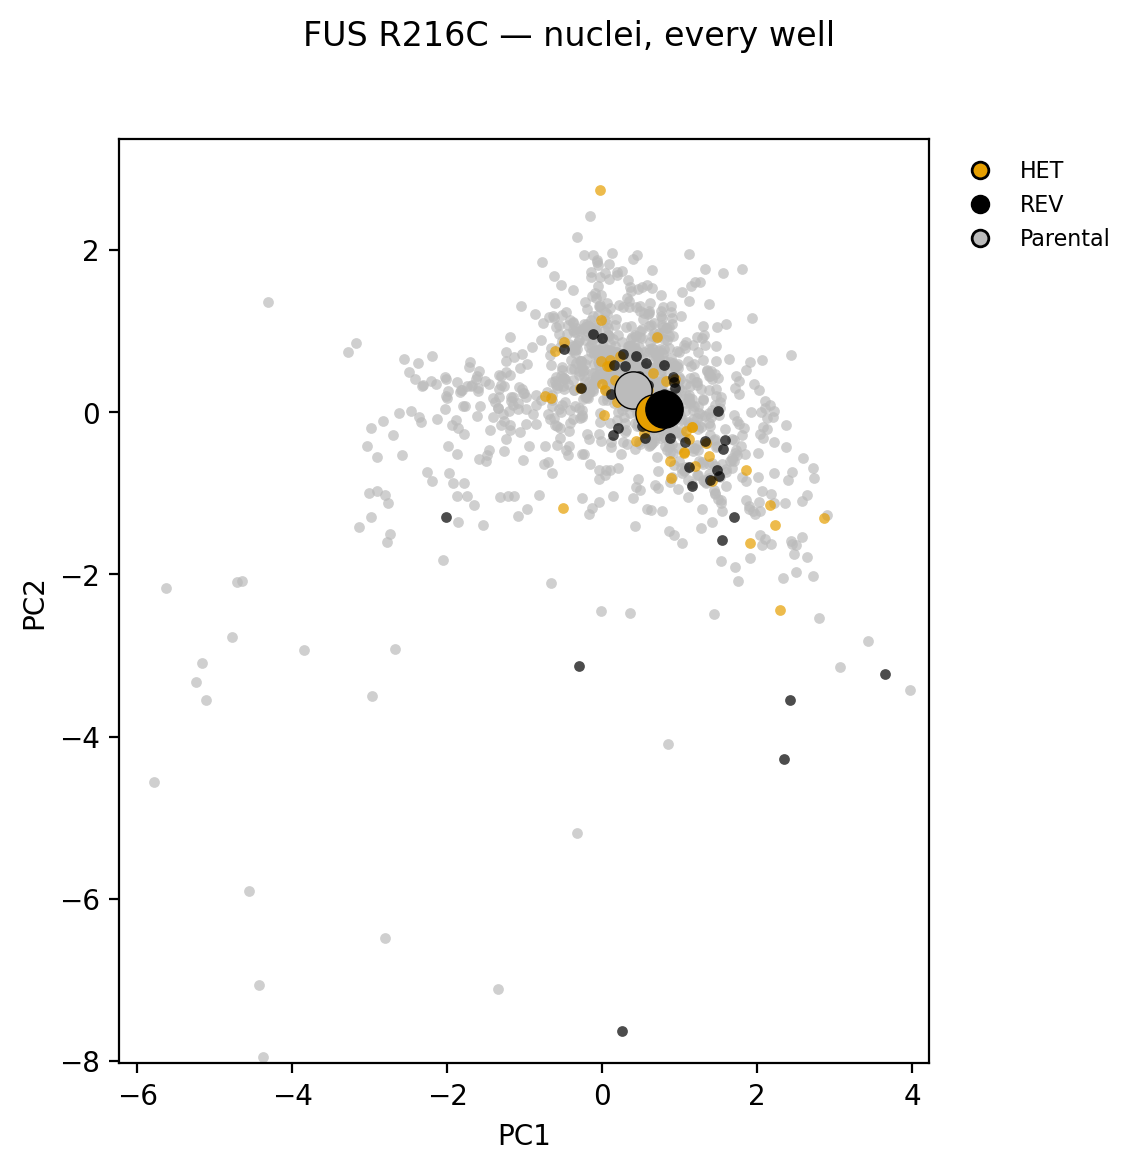

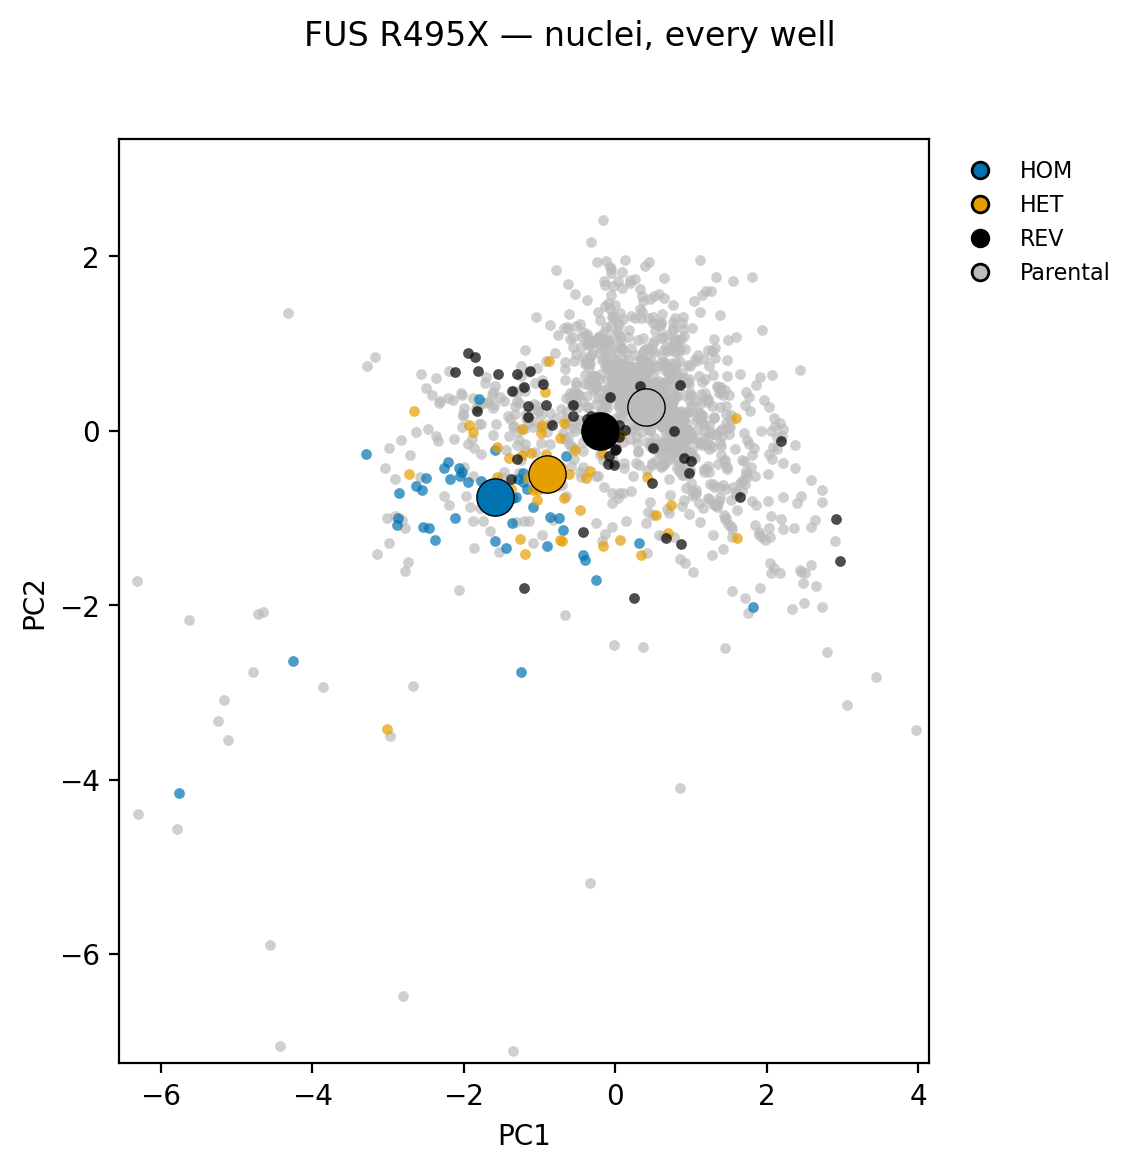

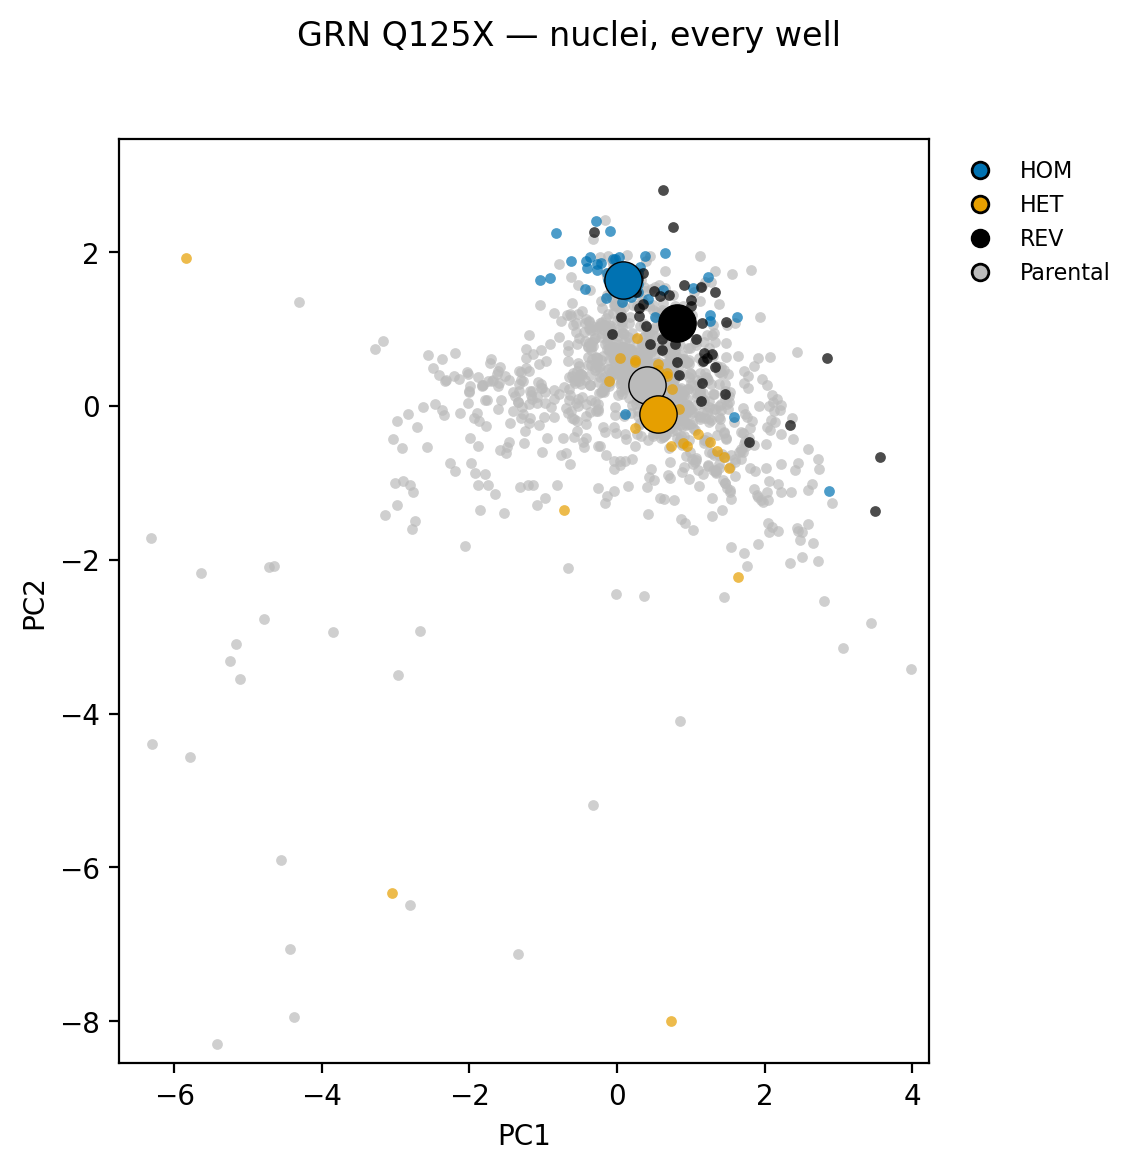

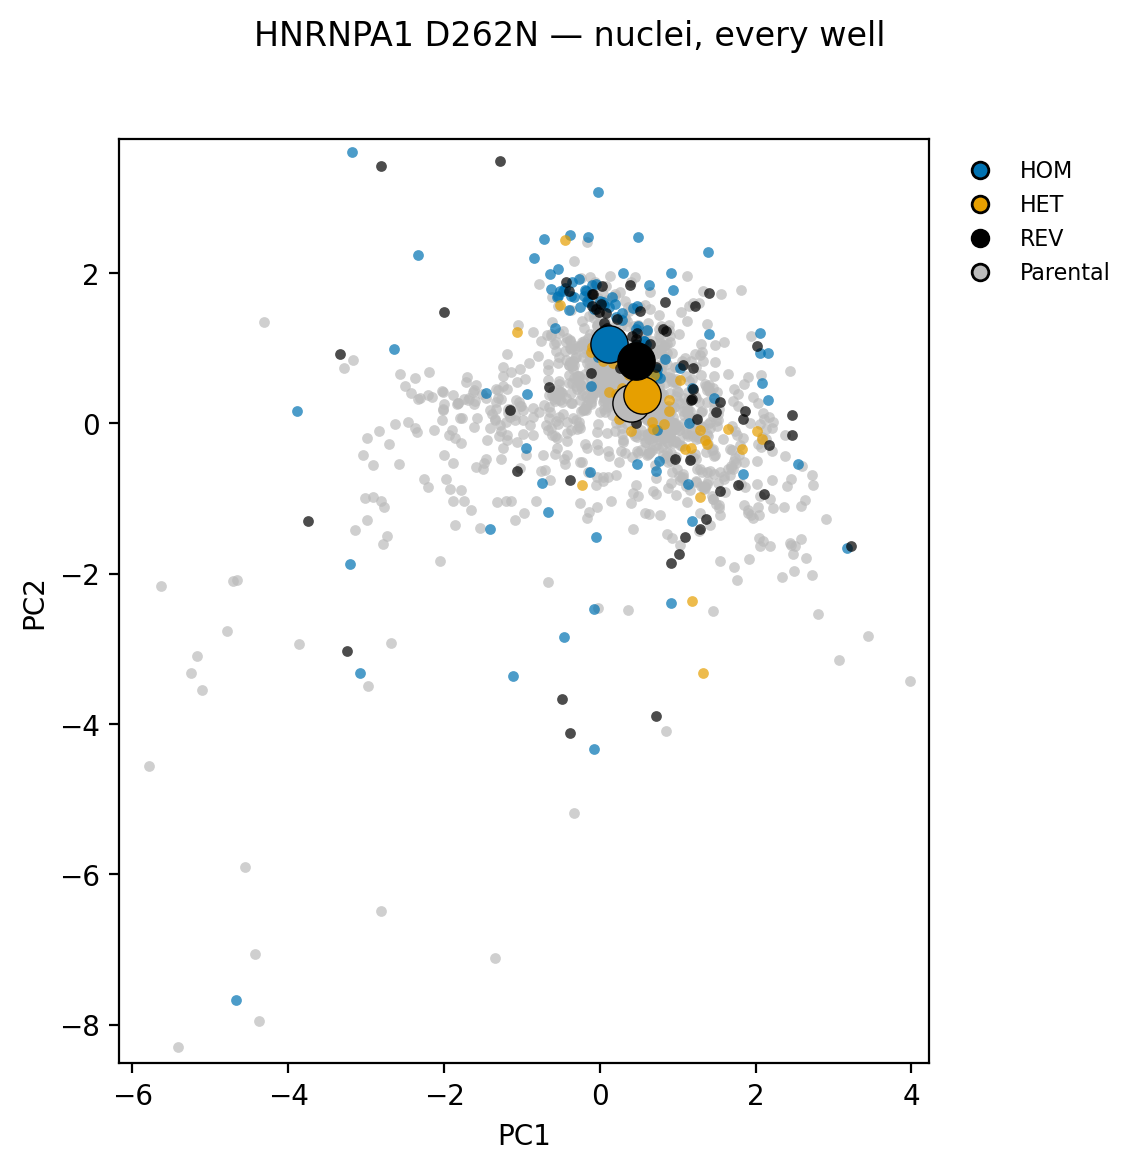

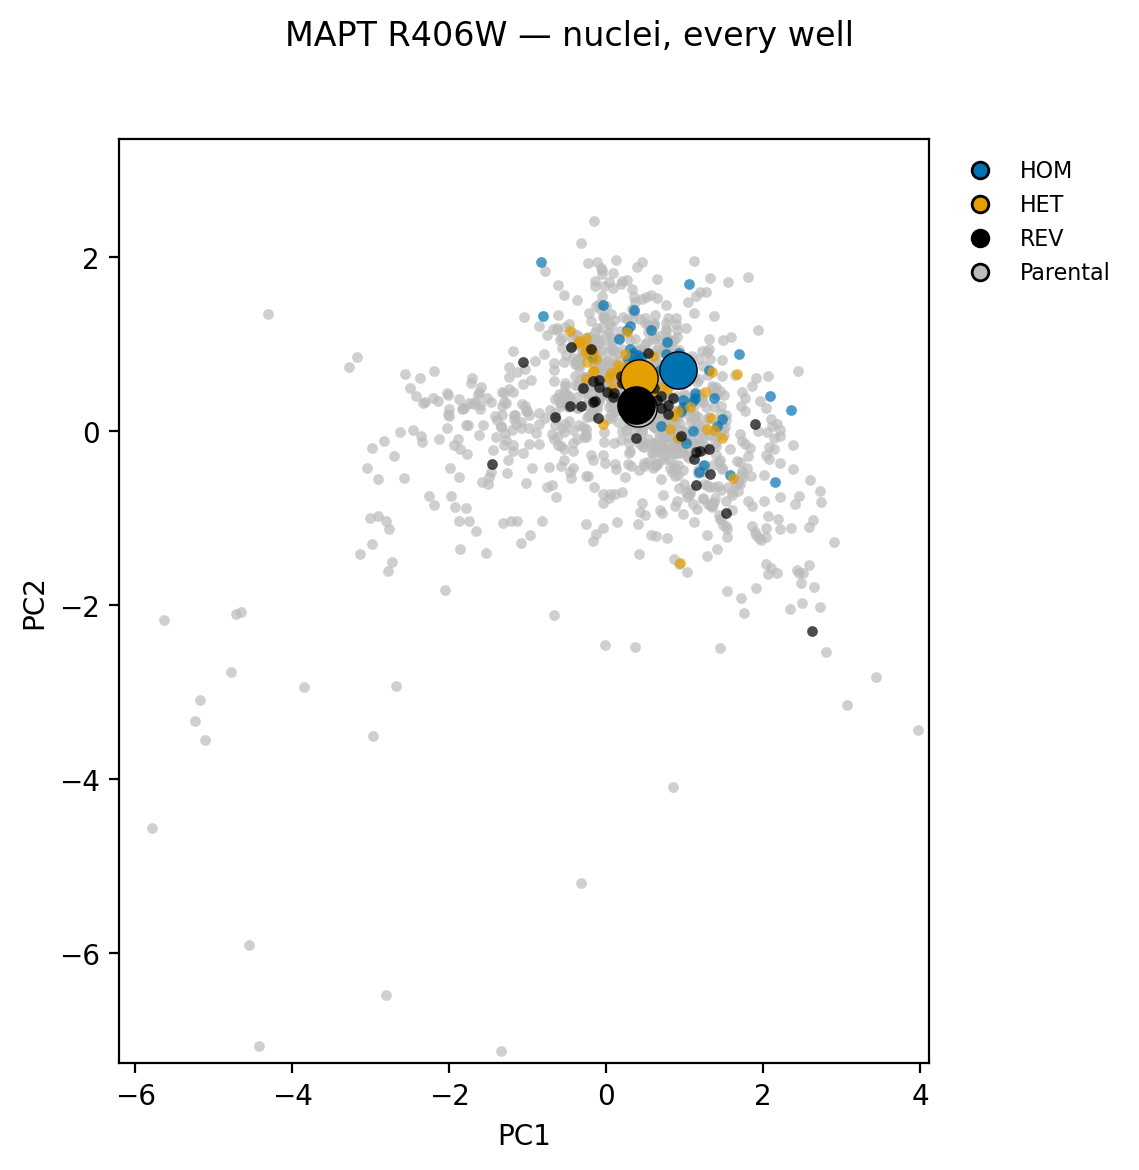

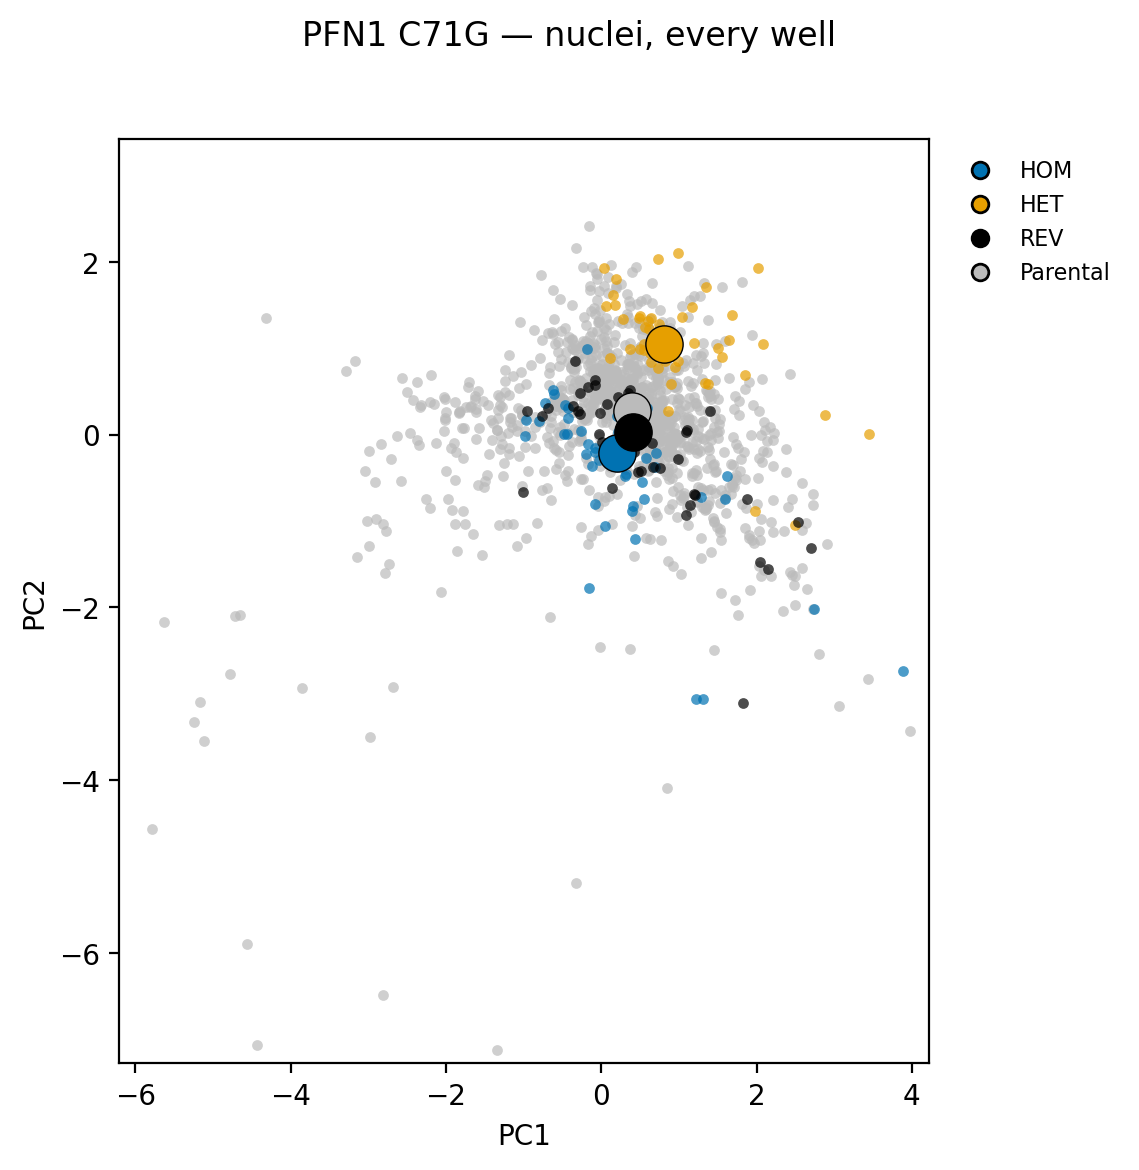

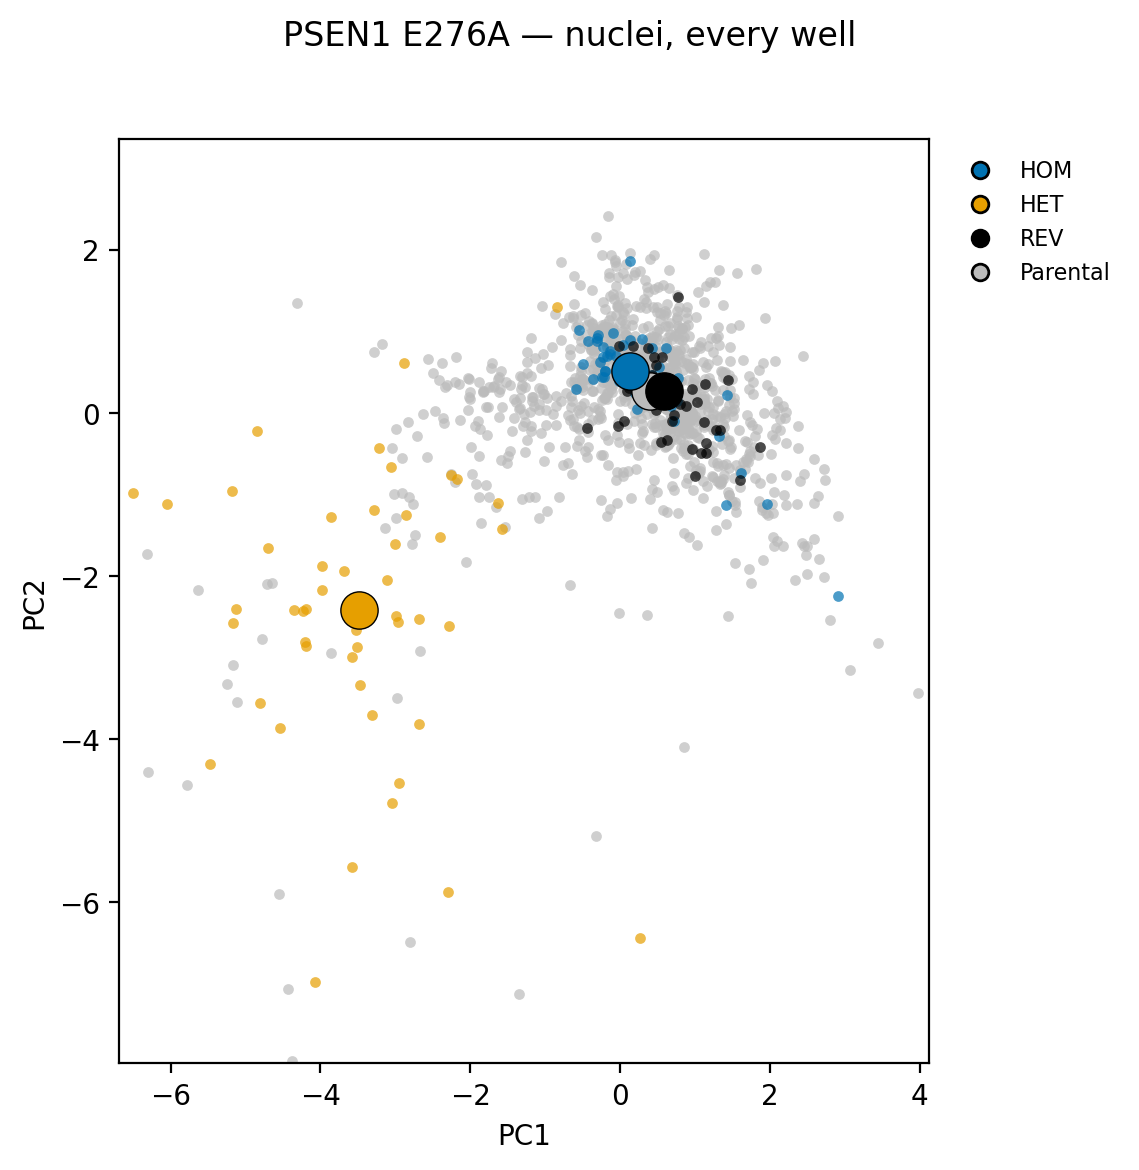

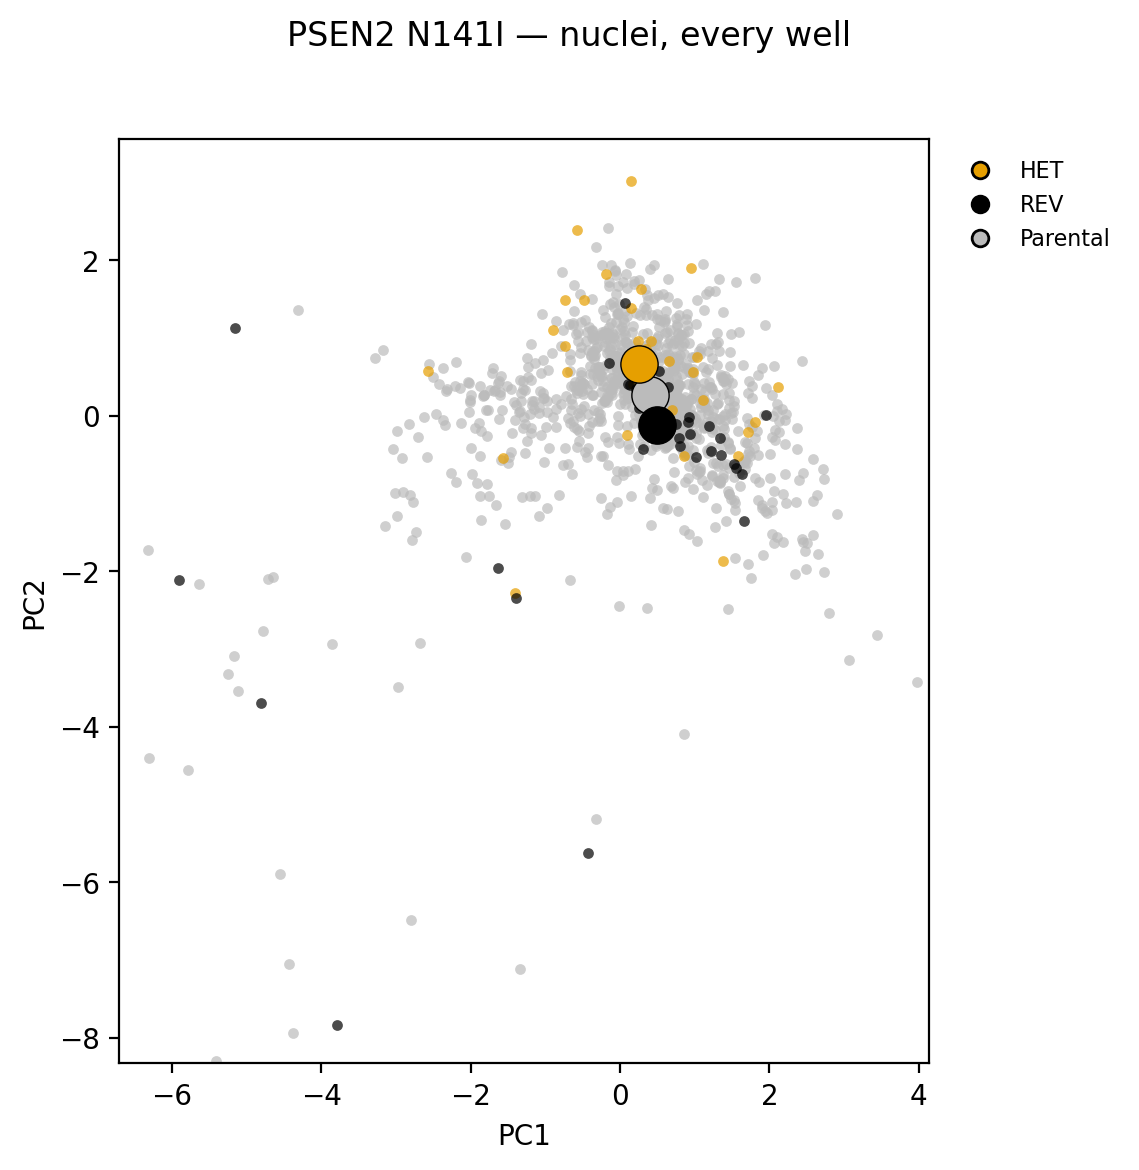

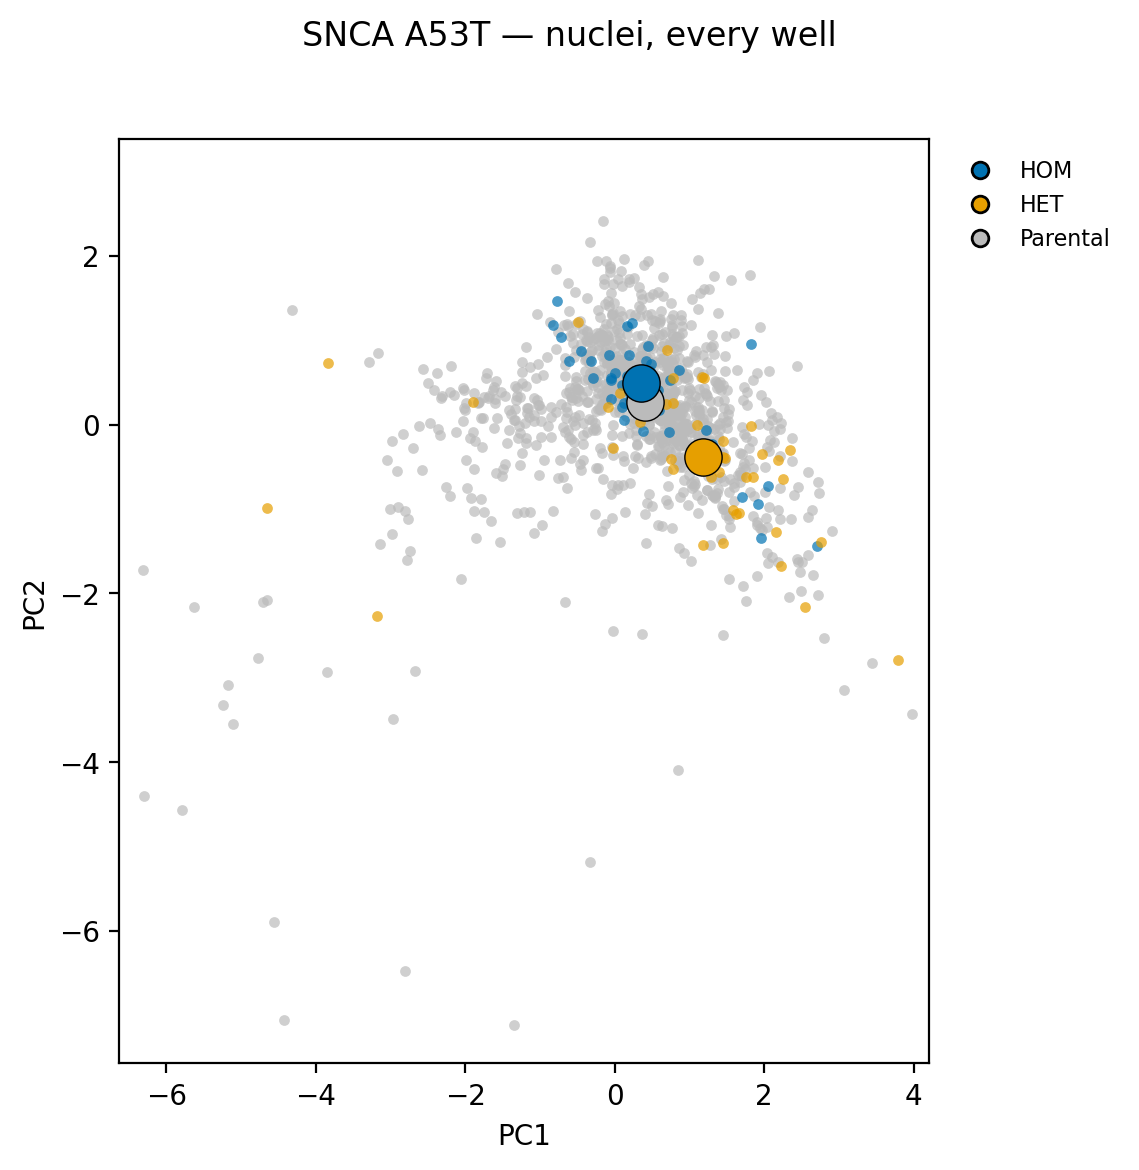

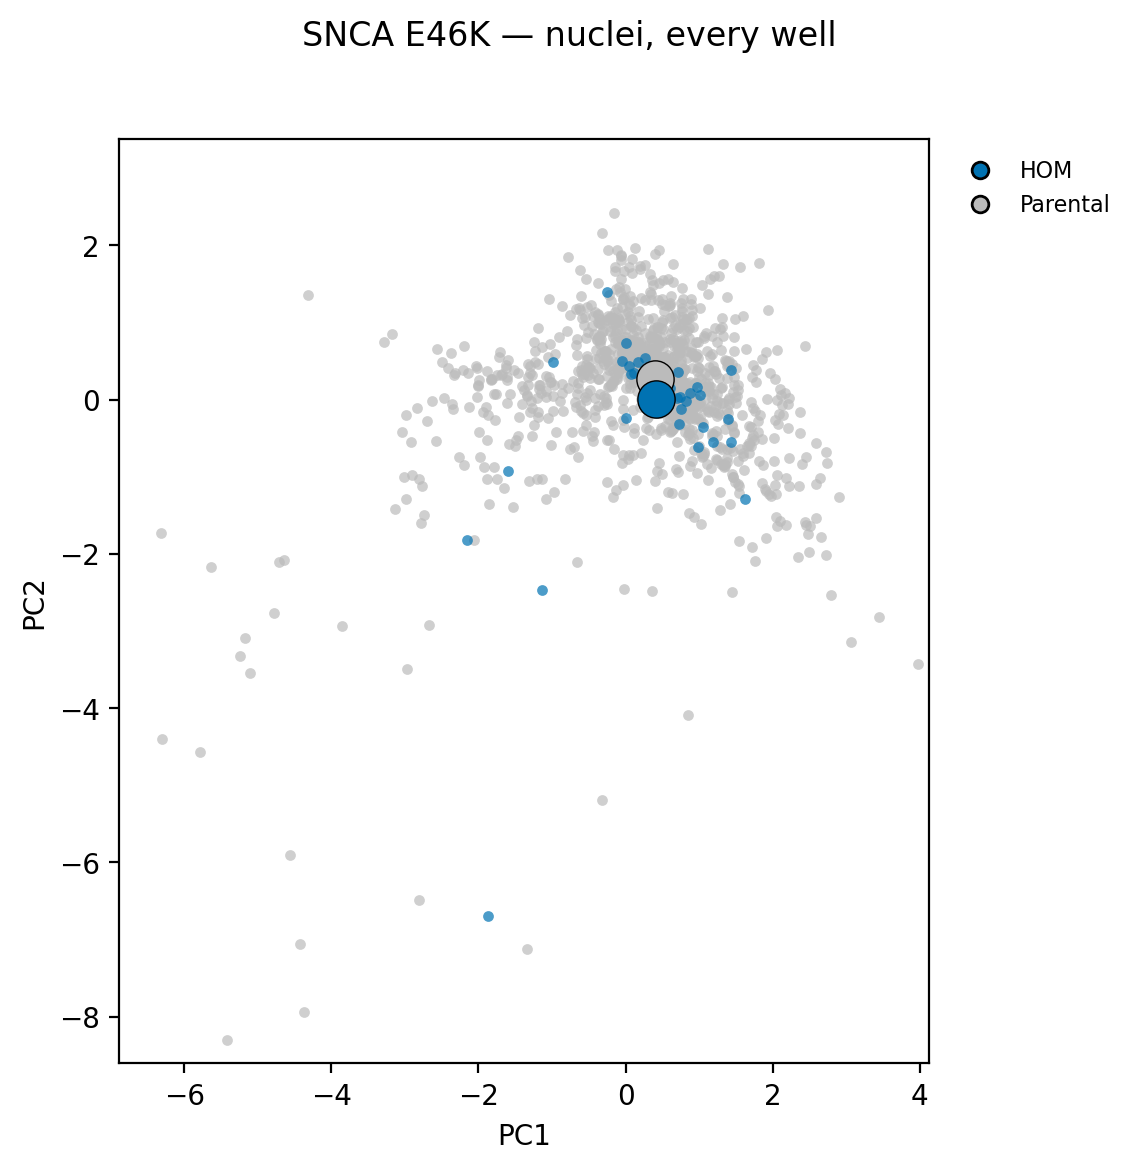

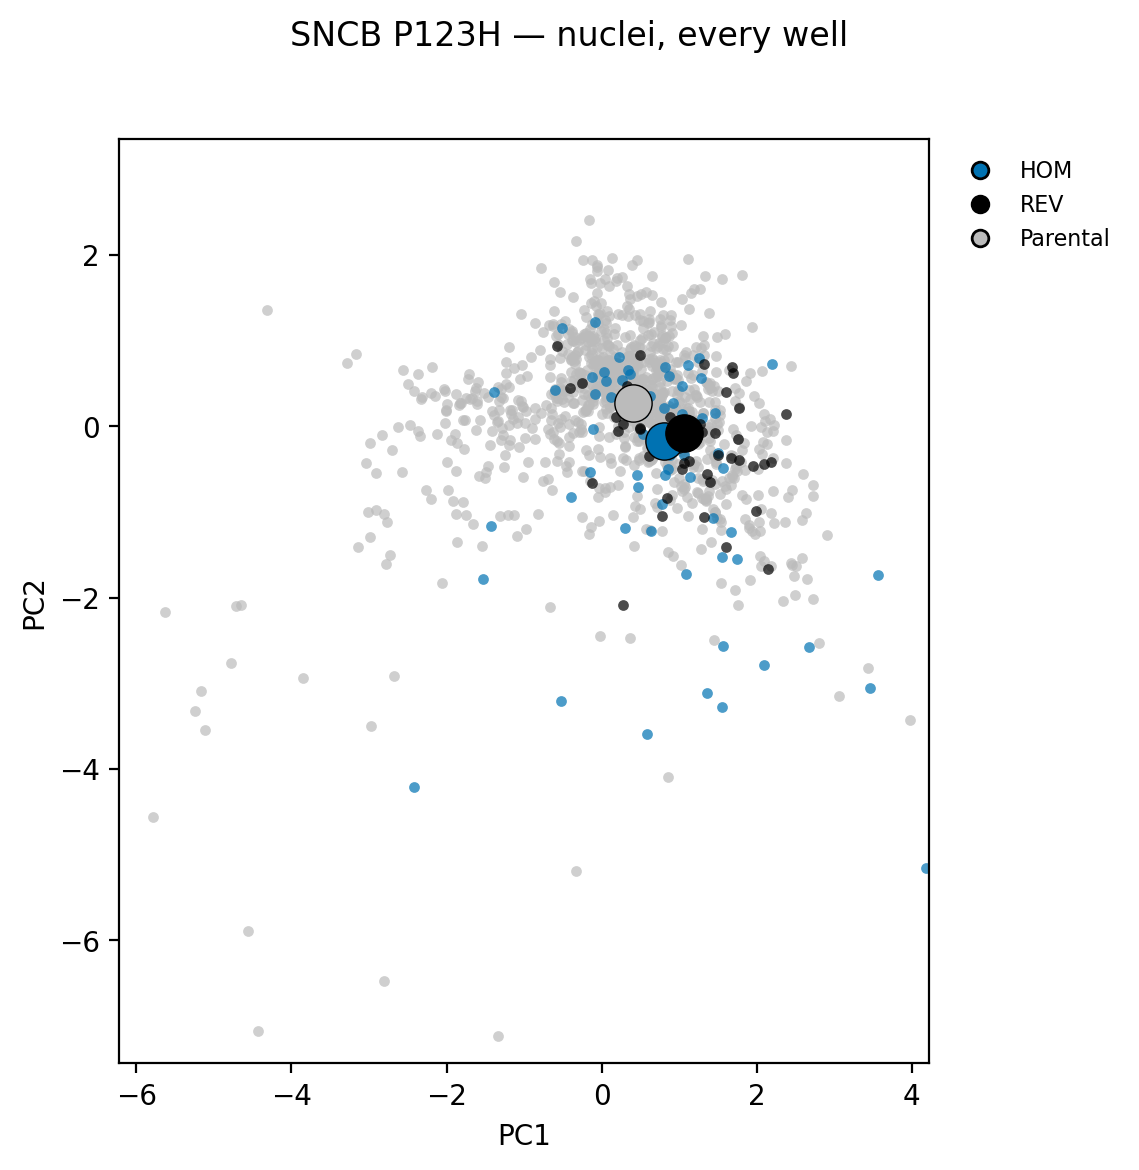

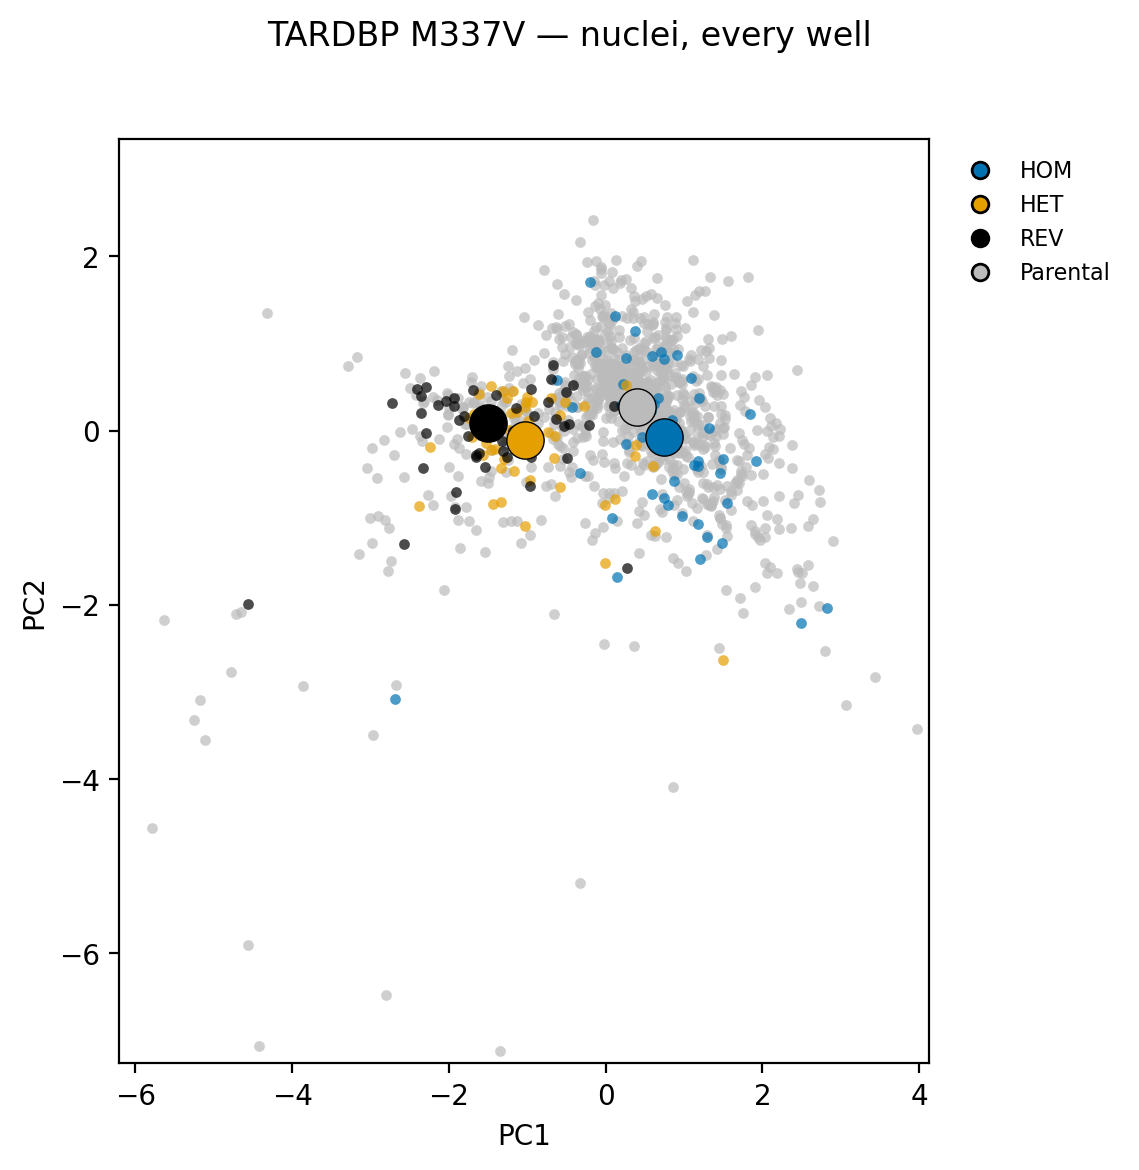

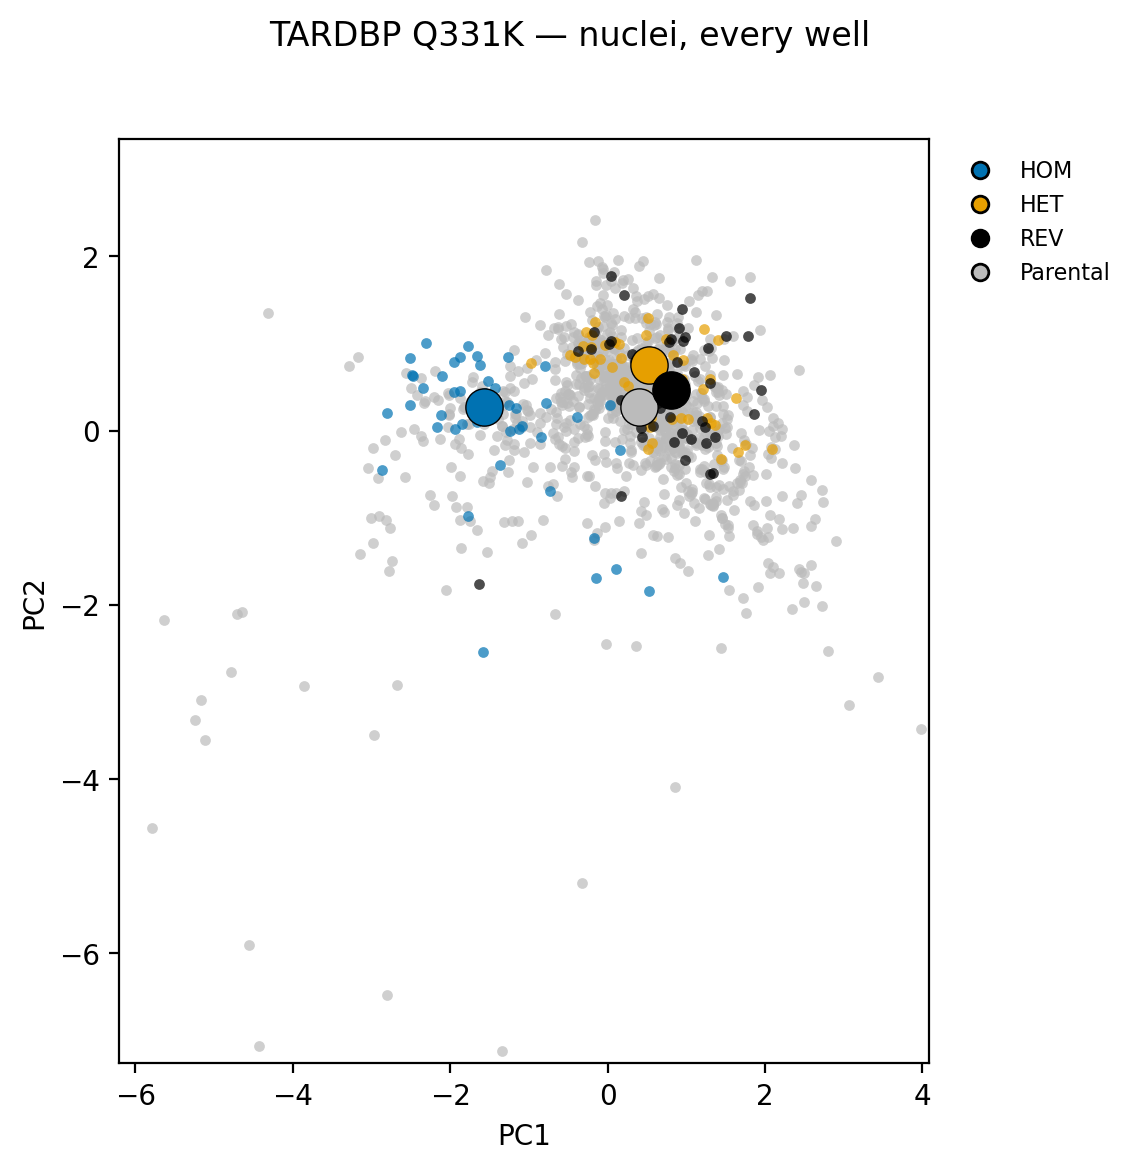

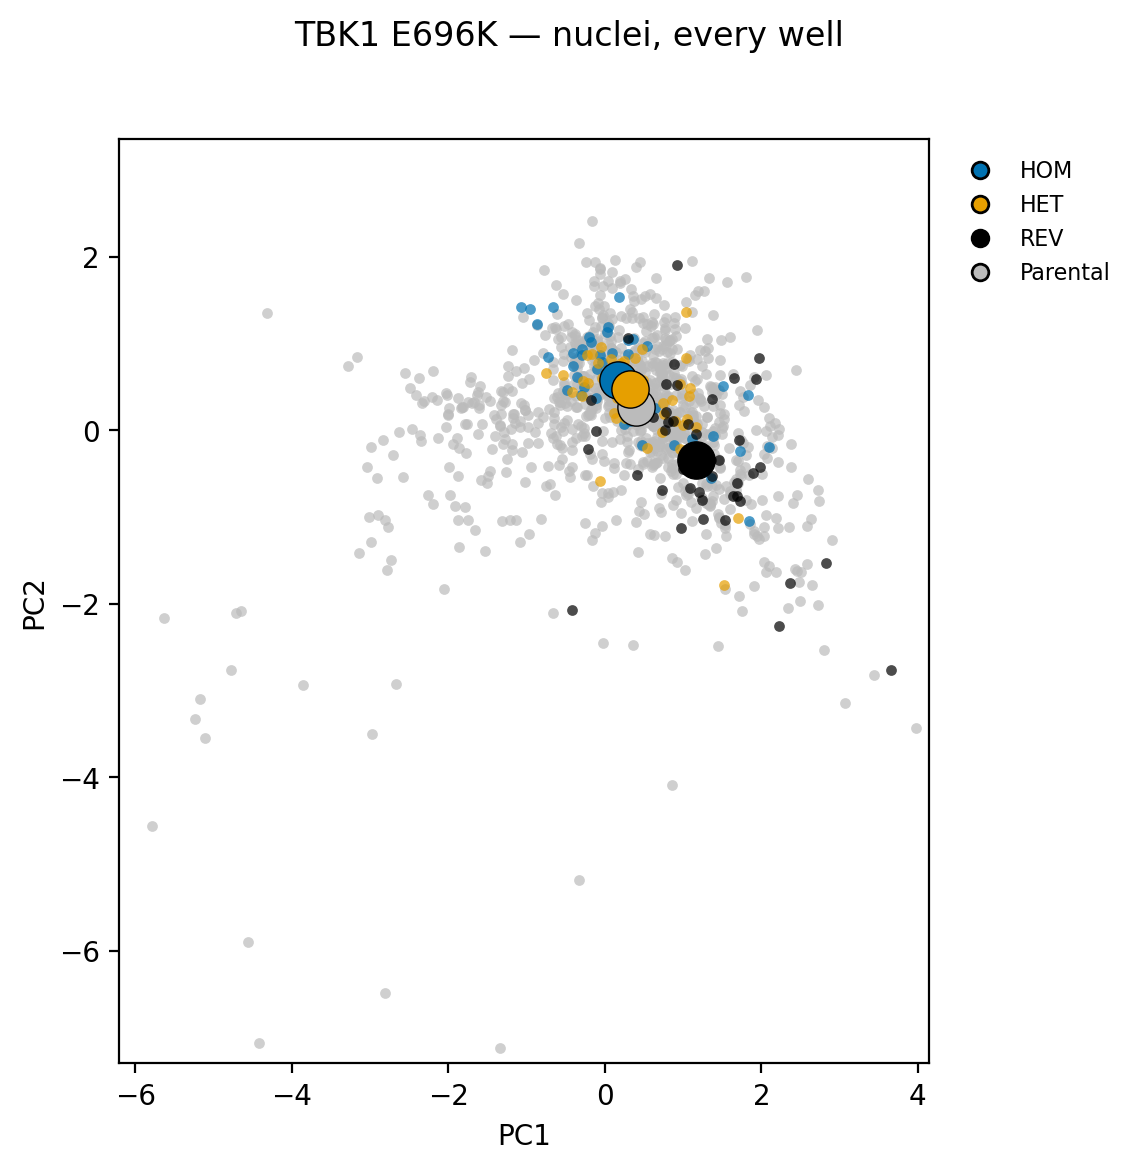

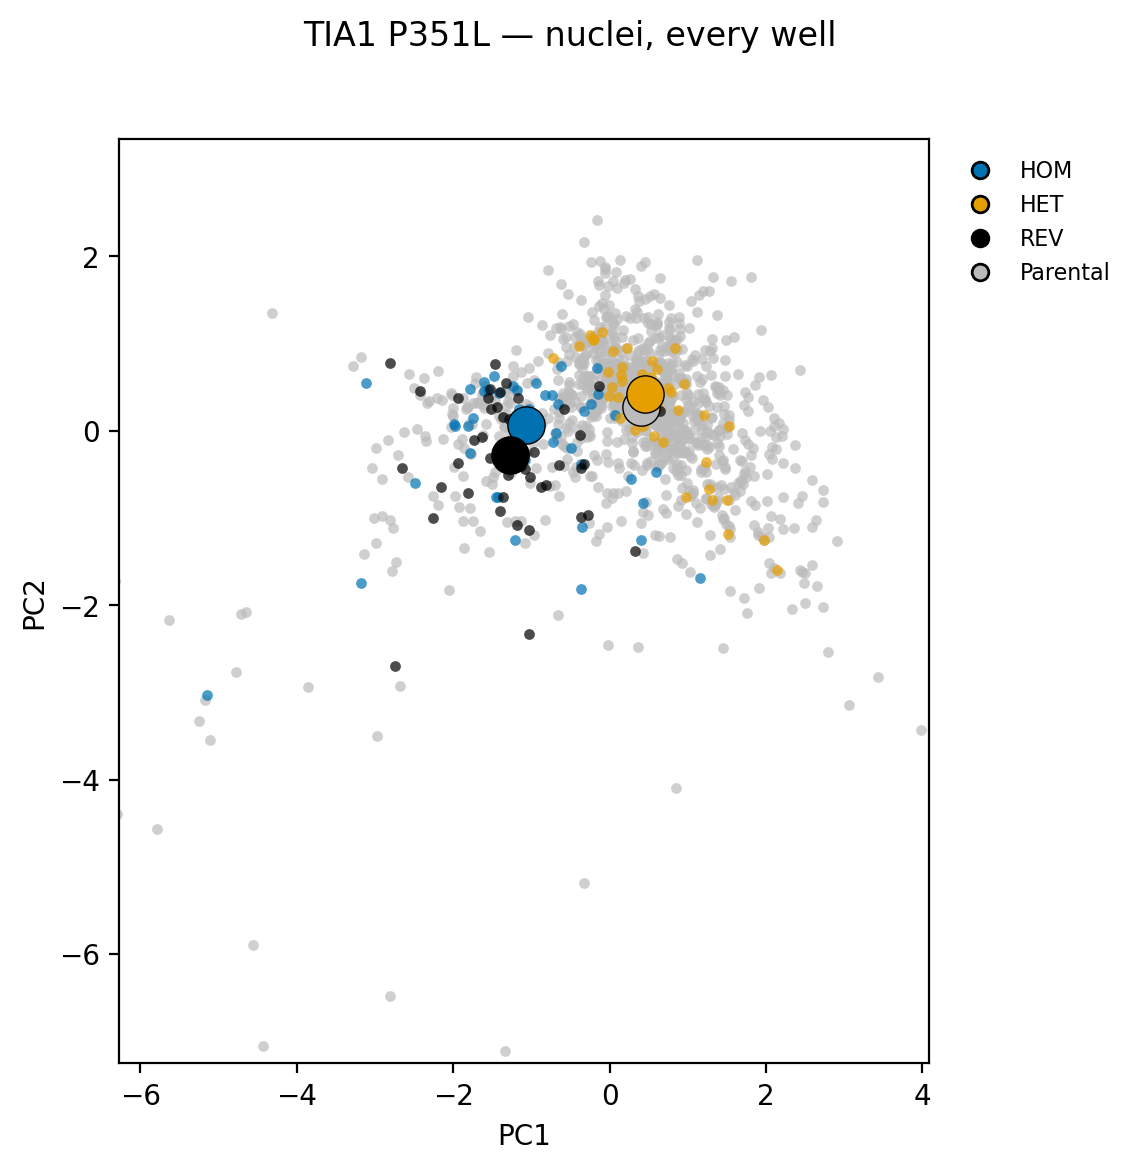

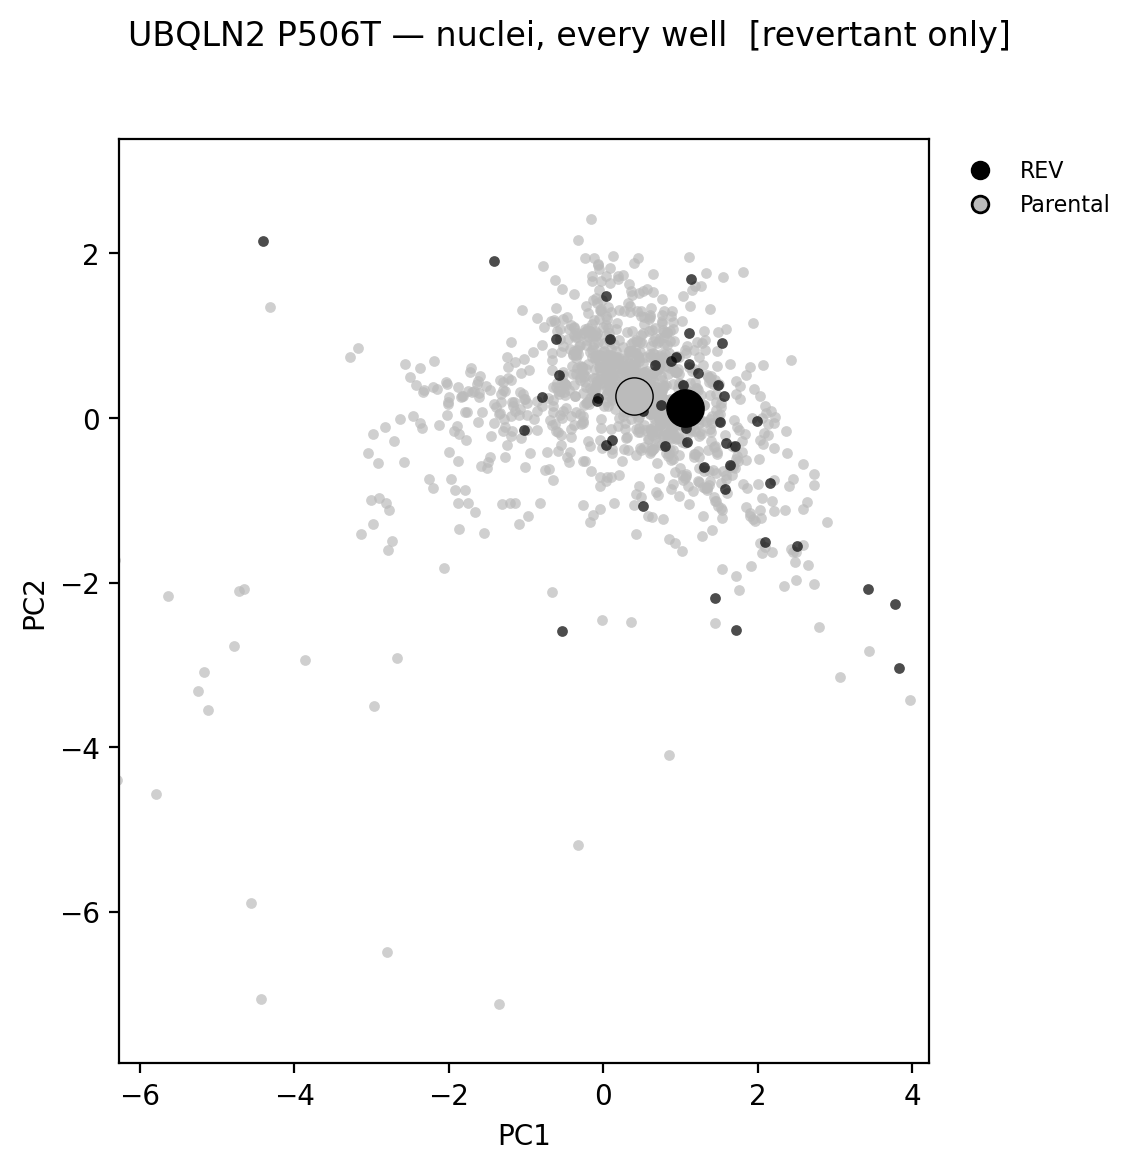

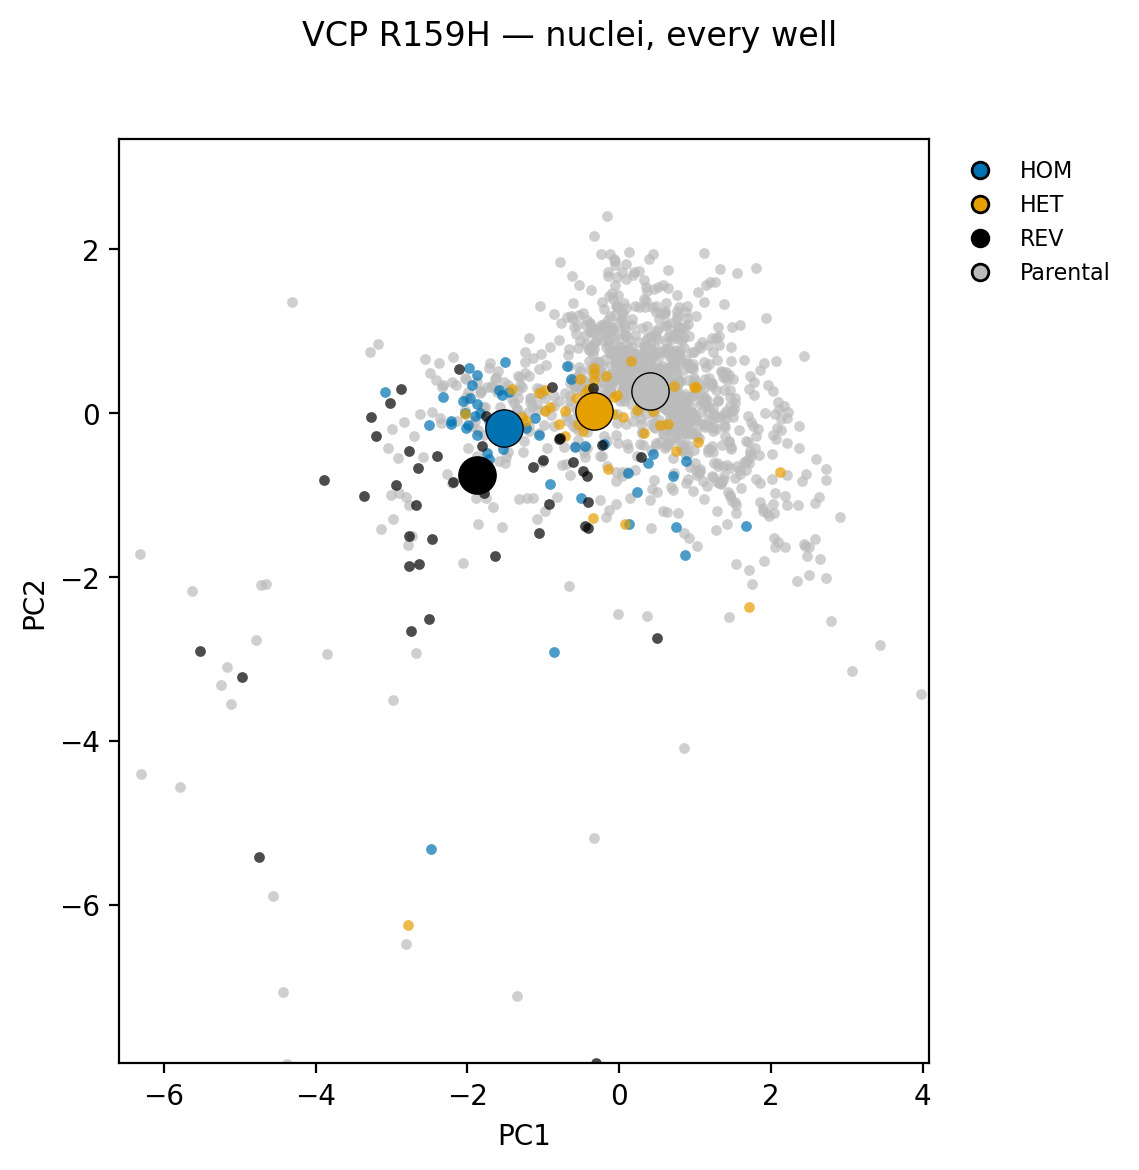

In [13]:
PARENTAL_NAME = "Parental"
GENO_COLORS = {"Parental": "#BBBBBB", "HET": "#E69F00", "HOM": "#0072B2",
               "REV": "#000000", "OTHER": "#F0E442"}
GENO_ORDER = ["HOM", "HET", "REV", "Parental"]

def _color_key(d):
    name = d["Genotype_Name"].astype(str).str.strip()
    is_par = name.str.upper() == PARENTAL_NAME.upper()
    zyg = name.str.split().str[-1].str.upper()
    return np.where(is_par, "Parental", zyg)

def variant_pca(df, gene, variant, pcx="PC1", pcy="PC2", parental=None,
                s=15, alpha=0.7, s_centroid=180, pad=1.5):
    src = df[(df["Gene"] == gene) & (df["Variant"] == variant)].copy()
    if parental is not None and not parental.empty:
        src = pd.concat([src, parental], ignore_index=True)
    if src.empty:
        print(f"[skip] no rows for {gene} {variant}"); return
    src["_ckey"] = _color_key(src)
    nonpar = src.loc[src["_ckey"] != "Parental", "_ckey"]
    note = "" if nonpar.isin(["HOM", "HET"]).any() else "  [revertant only]"

    px, py = src[pcx].dropna(), src[pcy].dropna()
    x_lo, x_hi = px.quantile(.01) - pad, px.quantile(.99) + pad
    y_lo, y_hi = py.quantile(.01) - pad, py.quantile(.99) + pad
    keys = [k for k in GENO_ORDER if k in src["_ckey"].unique()]
    draw = [k for k in keys if k == "Parental"] + [k for k in keys if k != "Parental"]

    fig, ax = plt.subplots(figsize=(6, 6), dpi=200)
    fig.subplots_adjust(right=0.80)
    for k in draw:
        gg = src[src["_ckey"] == k]
        ax.scatter(gg[pcx], gg[pcy], s=s, alpha=alpha,
                   color=GENO_COLORS.get(k, GENO_COLORS["OTHER"]),
                   linewidths=0, rasterized=True)
    for k in draw:
        gg = src[src["_ckey"] == k]
        if not gg.empty:
            ax.scatter(gg[pcx].median(), gg[pcy].median(), s=s_centroid,
                       color=GENO_COLORS.get(k, GENO_COLORS["OTHER"]),
                       edgecolor="k", linewidths=0.5, zorder=5)
    ax.set_xlim(x_lo, x_hi); ax.set_ylim(y_lo, y_hi)
    ax.set_xlabel(pcx); ax.set_ylabel(pcy)
    handles = [Line2D([0], [0], marker="o", linestyle="", markersize=6,
               markerfacecolor=GENO_COLORS.get(k, GENO_COLORS["OTHER"]),
               markeredgecolor="k", label=k) for k in keys]
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1.0),
              frameon=False, fontsize=8)
    fig.suptitle(f"{gene} {variant} — nuclei, every well{note}", y=0.98)
    plt.show()

# driver
well_df = well_level
is_par = well_df["Genotype_Name"].astype(str).str.strip().str.upper() == PARENTAL_NAME.upper()
parental_all = well_df[is_par].copy()
variants = (well_df.loc[~is_par, ["Gene", "Variant"]]
            .dropna().drop_duplicates().sort_values(["Gene", "Variant"]))
for gene, variant in variants.itertuples(index=False):
    variant_pca(well_df, gene, variant, parental=parental_all)